# Avance 5: Modelo Final (PASTIS Dataset)

**Dataset:** PASTIS (Sentinel-2 / Sentinel-1 Satellite Time Series)  
**Marco de Trabajo:** Metodología CRISP-ML(Q) — Fase de Modeling  
**Equipo:** 13

---

## Tabla de Contenidos Metodológica

### 1. Configuración del Entorno y Carga de Datos
- Recuperación de las particiones oficiales de PASTIS utilizadas en los Avances 3 y 4.
- Extracción de las mismas 52 características espectrales y temporales por píxel.
- Preparación de los conjuntos de entrenamiento, validación y prueba.

### 2. Modelos Individuales de Referencia
- Recuperación de las configuraciones de LDA y MLP evaluadas en el Avance 4.
- Inclusión de Regresión Logística como tercer modelo para las combinaciones heterogéneas.

### 3. Ensambles Homogéneos
- Entrenamiento de Random Forest y Extra Trees.
- Optimización de hiperparámetros mediante búsqueda aleatoria y validación cruzada agrupada por parche.

### 4. Ensambles Heterogéneos
- Combinación de modelos individuales mediante Voting y Stacking.
- Comparación de estrategias que utilizan algoritmos de distintas familias.

### 5. Comparación y Selección del Modelo Final
- Tabla comparativa con el mejor modelo individual del Avance 4 y los cuatro ensambles.
- Selección según Macro F1 en validación; reporte de Accuracy, Macro IoU y tiempos.

### 6. Evaluación con Datos No Vistos
- Evaluación del modelo seleccionado en el fold 5 de PASTIS.
- Matriz de confusión, curvas ROC y Precisión–Recall e importancia por permutación.

### 7. Conclusiones Metodológicas CRISP-ML(Q)
- Síntesis del procedimiento, criterios de selección y limitaciones identificadas.

### EXTRA. Pruebas Exploratorias de Segmentación y Fenología
- Evaluación de las cinco características más influyentes del Avance 4.
- Prueba de segmentación con una U-Net pequeña.
- Prueba con un modelo de lenguaje que genera descripciones de series NDVI y comparación cuantitativa de perfiles fenológicos.

### Declaración sobre el uso de herramientas de inteligencia artificial

## 1. Configuración del Entorno y Carga de Datos

Se trabaja con PASTIS y con las mismas **52 características por píxel** utilizadas en los Avances 3 y 4. Estas variables reúnen diez bandas Sentinel-2, tres índices de vegetación y cuatro estadísticas de la serie temporal: media, desviación estándar, mínimo y máximo.

Se conservan los folds oficiales: **1–3 para entrenamiento, 4 para validación y 5 para prueba**. Para mantener un costo de cómputo manejable en Colab, se selecciona una muestra reproducible de patches y píxeles dentro de cada partición. El modelo no utiliza las imágenes de prueba durante el ajuste ni la selección.

La etiqueta **Void (19)** identifica píxeles sin una clase semántica válida. Se excluye tanto del entrenamiento como de las métricas principales. El fondo (0) permanece como categoría válida. Esta decisión se aplica también al experimento complementario con U-Net.

In [ ]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO Y LIBRERÍAS
# ==============================================================================

# Librerías estándar de Python
import os
import io
import sys
import json
import time
import pickle
import platform
import threading
import warnings
from contextlib import redirect_stderr
from concurrent.futures import ThreadPoolExecutor

# Silenciar avisos también en los procesos paralelos de la búsqueda de hiperparámetros
os.environ["PYTHONWARNINGS"] = "ignore"
os.environ["KAGGLEHUB_VERBOSITY"] = "error"

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Procesamiento y seguimiento
from tqdm.auto import tqdm

# Estadística (distribuciones para la búsqueda de hiperparámetros)
import scipy
from scipy.stats import loguniform, randint, uniform, skew

# Machine Learning — modelos individuales (NO ensambles)
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, RobustScaler,
                                   PowerTransformer, QuantileTransformer)
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Random Forest: se usa ÚNICAMENTE como referencia del baseline (es un ensamble)
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, VotingClassifier, StackingClassifier)

# Selección de modelos y métricas
from sklearn.experimental import enable_halving_search_cv  # noqa: F401 (habilita HalvingRandomSearchCV)
from sklearn.model_selection import (RandomizedSearchCV, HalvingRandomSearchCV,
                                     GroupKFold, cross_val_score)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, jaccard_score, classification_report,
    confusion_matrix, make_scorer, roc_curve, auc, precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# Acceso a datasets
import kagglehub

# ------------------------------------------------------------------------------
# PARÁMETROS DEL EXPERIMENTO
# ------------------------------------------------------------------------------
MODO_RAPIDO = False   # True -> corrida reducida (menos parches y menos iteraciones) para pruebas

if MODO_RAPIDO:
    N_PARCHES = {"train": 40, "val": 10, "test": 10}
    PIXELS_POR_PARCHE = 200
    MAX_MUESTRAS_ENTRENAMIENTO = 6000
    MAX_MUESTRAS_BUSQUEDA = 4000
    MAX_MUESTRAS_STACKING = 4000
else:
    N_PARCHES = {"train": 100, "val": 30, "test": 30}
    PIXELS_POR_PARCHE = 300
    MAX_MUESTRAS_ENTRENAMIENTO = 15000
    MAX_MUESTRAS_BUSQUEDA = 6000
    MAX_MUESTRAS_STACKING = 8000

CV_FOLDS = 2                      # CV agrupada por patch para ensambles
DATASET_KAGGLE = "a01634782/pastis"
# Fondo (0) y 18 cultivos (1-18) son etiquetas válidas.
# La etiqueta 19 (Void) indica píxeles que se excluyen del aprendizaje y la evaluación.
VOID_LABEL = 19
CLASES = list(range(19))
N_JOBS = 2  # Limita la carga de CPU y evita paralelismo excesivo

# Nombres de las clases semánticas de PASTIS (según la documentación del dataset)
NOMBRES_CLASES = {
    0: "Fondo", 1: "Pradera", 2: "Trigo blando de invierno", 3: "Maíz",
    4: "Cebada de invierno", 5: "Colza de invierno", 6: "Cebada de primavera",
    7: "Girasol", 8: "Vid", 9: "Remolacha", 10: "Triticale de invierno",
    11: "Trigo duro de invierno", 12: "Frutas, hortalizas y flores", 13: "Papa",
    14: "Forraje leguminoso", 15: "Soya", 16: "Huerto", 17: "Cereal mixto",
    18: "Sorgo", 19: "Etiqueta nula (void)",
}

# Reproducibilidad
SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore")

# Configuración de visualizaciones
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Verificación de hardware y versiones (scikit-learn se ejecuta en CPU)
print("=== VERIFICACIÓN DEL ENTORNO ===")
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__,
      "| numpy:", np.__version__, "| pandas:", pd.__version__)
print("Núcleos de CPU disponibles:", os.cpu_count())
print("Modo rápido:", MODO_RAPIDO)
print("Clases evaluadas: 0-18; etiqueta Void (19) excluida")
print("Parches por partición:", N_PARCHES)
print("Píxeles por parche:", PIXELS_POR_PARCHE)
print("Máximo de píxeles para entrenar modelos:", MAX_MUESTRAS_ENTRENAMIENTO)
print("Máximo para búsqueda:", MAX_MUESTRAS_BUSQUEDA)
print("Máximo para Stacking:", MAX_MUESTRAS_STACKING)
print("Entorno configurado correctamente.")

=== VERIFICACIÓN DEL ENTORNO ===
Python: 3.13.16 | scikit-learn: 1.6.1 | numpy: 2.1.3 | pandas: 2.2.3
Núcleos de CPU disponibles: 2
Modo rápido: False
Clases evaluadas: 0-18; etiqueta Void (19) excluida
Parches por partición: {'train': 100, 'val': 30, 'test': 30}
Píxeles por parche: 300
Máximo de píxeles para entrenar modelos: 15000
Máximo para búsqueda: 6000
Máximo para Stacking: 8000
Entorno configurado correctamente.


In [ ]:
# ==============================================================================
# 1.2 CARGA DEL DATASET PASTIS (RUTAS LOCALES Y DESCARGA SELECTIVA)
# ==============================================================================
# Se conserva el acceso selectivo utilizado en el Avance 4, pero primero se
# aprovechan los archivos que ya estén disponibles en la sesión de Colab.
# Nunca se activa automáticamente la descarga del dataset completo.

import re
from pathlib import Path

FUENTES_PASTIS = [
    Path('/kaggle/input/pastis/PASTIS'),
    Path('/root/.cache/kagglehub/datasets/a01634782/pastis/versions/1/PASTIS'),
    Path('/content/PASTIS'),
    Path('/content/pastis/PASTIS'),
]

# Si KaggleHub utilizó otra versión del dataset, también se incorpora.
carpeta_versiones = Path('/root/.cache/kagglehub/datasets/a01634782/pastis/versions')
if carpeta_versiones.is_dir():
    for version in sorted(carpeta_versiones.iterdir(), reverse=True):
        if (version / 'PASTIS').is_dir():
            FUENTES_PASTIS.append(version / 'PASTIS')

# Eliminar rutas repetidas sin perder la prioridad del montaje actual.
FUENTES_PASTIS = list(dict.fromkeys(FUENTES_PASTIS))

rutas_s2 = {}
rutas_target = {}
metadata_path = None

for fuente in FUENTES_PASTIS:
    if not fuente.is_dir():
        continue

    ruta_meta = fuente / 'metadata.geojson'
    if metadata_path is None and ruta_meta.is_file():
        metadata_path = str(ruta_meta)

    # Buscar imágenes y anotaciones disponibles en esa carpeta.
    for carpeta, _, archivos in os.walk(fuente):
        for nombre in archivos:
            s2 = re.fullmatch(r'S2_(\d+)\.npy', nombre)
            target = re.fullmatch(r'TARGET_(\d+)\.npy', nombre)
            if s2:
                rutas_s2.setdefault(int(s2.group(1)), os.path.join(carpeta, nombre))
            elif target:
                rutas_target.setdefault(int(target.group(1)), os.path.join(carpeta, nombre))

# El Avance 4 descargaba selectivamente el archivo de metadatos.
# Se recurre al mismo método únicamente si la sesión no lo conserva.
if metadata_path is None:
    print('Metadatos no disponibles localmente; intentando descarga selectiva...', flush=True)
    try:
        metadata_path = kagglehub.dataset_download(
            DATASET_KAGGLE, path='PASTIS/metadata.geojson'
        )
        if not os.path.isfile(metadata_path):
            raise FileNotFoundError(f'KaggleHub devolvió una ruta no válida: {metadata_path}')
    except Exception as exc:
        raise FileNotFoundError(
            'No se encontró metadata.geojson en esta sesión y la descarga selectiva '
            'tampoco funcionó. El dataset que estaba en una sesión anterior de Colab '
            'puede haber desaparecido al cambiar el entorno. Se necesita volver a '
            'montar PASTIS o restablecer el acceso al archivo metadata.geojson.'
        ) from exc

IDS_PARES_LOCALES = set(rutas_s2) & set(rutas_target)


def ruta_pastis(ruta_relativa):
    """Obtiene un archivo S2/TARGET localmente o mediante descarga selectiva."""
    nombre = os.path.basename(ruta_relativa)
    m_s2 = re.fullmatch(r'S2_(\d+)\.npy', nombre)
    m_target = re.fullmatch(r'TARGET_(\d+)\.npy', nombre)

    if m_s2:
        pid = int(m_s2.group(1))
        indice = rutas_s2
    elif m_target:
        pid = int(m_target.group(1))
        indice = rutas_target
    else:
        raise ValueError(f'Archivo PASTIS no reconocido: {ruta_relativa}')

    encontrado = indice.get(pid)
    if encontrado is not None and os.path.isfile(encontrado):
        return encontrado

    # Sin descarga completa: solo se solicita el archivo faltante.
    try:
        ruta = kagglehub.dataset_download(
            DATASET_KAGGLE, path=f'PASTIS/{ruta_relativa}'
        )
    except Exception as exc:
        raise FileNotFoundError(
            f'No se pudo acceder a PASTIS/{ruta_relativa}. '
            'El archivo no está disponible localmente y falló la descarga selectiva.'
        ) from exc

    if not os.path.isfile(ruta):
        raise FileNotFoundError(f'Archivo PASTIS no encontrado: {ruta_relativa}')
    indice[pid] = ruta
    return ruta


print('=== DATASET PASTIS ===')
print('Metadatos:', metadata_path)
print('Imágenes S2 locales:', len(rutas_s2))
print('Anotaciones TARGET locales:', len(rutas_target))
print('Pares locales completos:', len(IDS_PARES_LOCALES))
print('Acceso: primero archivos locales; después descarga selectiva si falta alguno.')


Metadatos no disponibles localmente; intentando descarga selectiva...


100%|██████████| 7.04M/7.04M [00:00<00:00, 14.5MB/s]

=== DATASET PASTIS ===
Metadatos: /root/.cache/kagglehub/datasets/a01634782/pastis/versions/1/PASTIS/metadata.geojson
Imágenes S2 locales: 0
Anotaciones TARGET locales: 0
Pares locales completos: 0
Acceso: primero archivos locales; después descarga selectiva si falta alguno.


In [ ]:
# ==============================================================================
# 1.3 METADATOS Y PARTICIONES OFICIALES
# ==============================================================================

# Cargar metadatos de PASTIS (GeoJSON -> DataFrame, no se requiere geometría)
with open(metadata_path, "r") as f:
    geojson = json.load(f)

metadata = pd.DataFrame([ft["properties"] for ft in geojson["features"]])

print("=== METADATOS PASTIS ===")
print("Número de registros:", len(metadata))
print("Columnas disponibles:", metadata.columns.tolist())

print("\nDistribución de folds:")
print(metadata["Fold"].value_counts().sort_index())

# Mismas particiones que el Avance 3
train_meta = metadata[metadata["Fold"].isin([1, 2, 3])].copy()
val_meta = metadata[metadata["Fold"] == 4].copy()
test_meta = metadata[metadata["Fold"] == 5].copy()

print("\n=== PARTICIONES ===")
print(f"Entrenamiento (folds 1-3): {len(train_meta):,} parches")
print(f"Validación    (fold 4):    {len(val_meta):,} parches")
print(f"Prueba        (fold 5):    {len(test_meta):,} parches")

# Verificar que no existan parches compartidos
ids_train = set(train_meta["ID_PATCH"].astype(int))
ids_val = set(val_meta["ID_PATCH"].astype(int))
ids_test = set(test_meta["ID_PATCH"].astype(int))

assert ids_train.isdisjoint(ids_val)
assert ids_train.isdisjoint(ids_test)
assert ids_val.isdisjoint(ids_test)

print("\nVerificación de separación: CORRECTA")

=== METADATOS PASTIS ===
Número de registros: 2433
Columnas disponibles: ['Fold', 'ID_PATCH', 'N_Parcel', 'Parcel_Cover', 'TILE', 'dates-S2', 'id']

Distribución de folds:
Fold
1    487
2    494
3    474
4    482
5    496
Name: count, dtype: int64

=== PARTICIONES ===
Entrenamiento (folds 1-3): 1,455 parches
Validación    (fold 4):    482 parches
Prueba        (fold 5):    496 parches

Verificación de separación: CORRECTA


In [ ]:
# ==============================================================================
# 1.4 EXTRACCIÓN DE CARACTERÍSTICAS (MISMA FUNCIÓN DEL AVANCE 3)
# ==============================================================================

bandas_s2 = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
variables = bandas_s2 + ["NDVI", "NDWI", "EVI"]
estadisticas = ["media", "std", "min", "max"]

nombres_features = [
    f"{estadistica}_{variable}"
    for estadistica in estadisticas
    for variable in variables
]


def extraer_caracteristicas(imagen):
    """(T, 10, H, W) -> matriz (H*W, 52) con estadísticas temporales por píxel."""

    # Reescalamiento de reflectancia
    img = imagen.astype(np.float32) / 10000.0

    # Limitar reflectancias negativas
    img = np.maximum(img, 0.0)

    # Bandas espectrales
    azul = img[:, 0]
    verde = img[:, 1]
    rojo = img[:, 2]
    nir = img[:, 6]

    eps = 1e-4

    # Índices espectrales estabilizados
    ndvi = (nir - rojo) / np.maximum(nir + rojo, eps)
    ndwi = (verde - nir) / np.maximum(verde + nir, eps)

    denominador_evi = nir + 6 * rojo - 7.5 * azul + 1
    denominador_evi = np.where(
        denominador_evi >= 0,
        np.maximum(denominador_evi, eps),
        np.minimum(denominador_evi, -eps)
    )

    evi = np.clip(2.5 * (nir - rojo) / denominador_evi, -3, 3)

    # Integrar bandas e índices
    indices = np.stack([ndvi, ndwi, evi], axis=1)
    datos = np.concatenate([img, indices], axis=1)

    # Estadísticas temporales
    features = np.concatenate([
        np.mean(datos, axis=0),
        np.std(datos, axis=0),
        np.min(datos, axis=0),
        np.max(datos, axis=0)
    ], axis=0)

    return features.reshape(features.shape[0], -1).T


print("=== CARACTERÍSTICAS ===")
print("Número de características por píxel:", len(nombres_features))
print("Ejemplo:", nombres_features[:5], "...")

=== CARACTERÍSTICAS ===
Número de características por píxel: 52
Ejemplo: ['media_B2', 'media_B3', 'media_B4', 'media_B5', 'media_B6'] ...


In [ ]:
# ==============================================================================
# 1.5 CONSTRUCCIÓN DE LOS CONJUNTOS DE ENTRENAMIENTO, VALIDACIÓN Y PRUEBA
# ==============================================================================
# Se mantienen los folds del Avance 4: entrenamiento 1-3, validación 4 y prueba 5.
# La caché se identifica también por los patches usados para evitar mezclar muestras.
import hashlib

CACHE = (
    '/content/pastis_avance5_cache.npz'
    if os.path.isdir('/content') else 'pastis_avance5_cache.npz'
)


def seleccionar_parches(df, cantidad, generador):
    ids = np.sort(df['ID_PATCH'].astype(int).to_numpy())
    ids_locales = np.array([pid for pid in ids if pid in IDS_PARES_LOCALES], dtype=int)

    # Si se conserva una muestra local suficiente, usarla evita solicitudes a
    # KaggleHub y mantiene cada partición dentro de su fold correspondiente.
    if len(ids_locales) >= min(cantidad, len(ids)):
        candidatos = ids_locales
    else:
        candidatos = ids  # los ausentes se obtendrán de manera selectiva

    elegidos = generador.choice(
        candidatos, size=min(cantidad, len(candidatos)), replace=False
    )
    return sorted(int(pid) for pid in elegidos)


generador = np.random.default_rng(SEED)
ids_elegidos = {
    'train': seleccionar_parches(train_meta, N_PARCHES['train'], generador),
    'val': seleccionar_parches(val_meta, N_PARCHES['val'], generador),
    'test': seleccionar_parches(test_meta, N_PARCHES['test'], generador),
}

firma_ids = hashlib.sha256(repr(ids_elegidos).encode('utf-8')).hexdigest()[:16]
firma = f'no_void_v2|{N_PARCHES}|{PIXELS_POR_PARCHE}|{SEED}|{firma_ids}'


def preparar_parche(patch_id):
    """Carga el patch y obtiene características temporales por píxel."""
    imagen_path = ruta_pastis(f'DATA_S2/S2_{patch_id}.npy')
    target_path = ruta_pastis(f'ANNOTATIONS/TARGET_{patch_id}.npy')
    imagen = np.load(imagen_path)
    target = np.load(target_path)

    X = extraer_caracteristicas(imagen)
    y = target[0].reshape(-1)

    # Selección únicamente de píxeles con etiquetas semánticas válidas.
    # Esto evita que Void (19) se trate como cultivo en los clasificadores.
    indices_validos = np.flatnonzero((y >= 0) & (y != VOID_LABEL) & (y < 19))
    if len(indices_validos) == 0:
        raise ValueError(f'Patch {patch_id} sin píxeles con clases válidas')
    g = np.random.default_rng(SEED + int(patch_id))
    idx = g.choice(
        indices_validos,
        size=min(PIXELS_POR_PARCHE, len(indices_validos)),
        replace=False
    )
    return X[idx].astype(np.float32), y[idx].astype(np.int16)


def construir_conjunto(ids, nombre):
    # Descarga secuencial si faltan archivos; lectura paralela si todo es local.
    todos_locales = all(pid in IDS_PARES_LOCALES for pid in ids)
    workers = 3 if todos_locales else 1

    with ThreadPoolExecutor(max_workers=workers) as ejecutor:
        resultados = list(tqdm(
            ejecutor.map(preparar_parche, ids),
            total=len(ids), desc=nombre, file=sys.stdout
        ))

    X = np.vstack([r[0] for r in resultados])
    y = np.concatenate([r[1] for r in resultados])
    grupos = np.concatenate([
        np.full(len(r[1]), pid, dtype=np.int64)
        for r, pid in zip(resultados, ids)
    ])
    return X, y, grupos


inicio = time.time()
usar_cache = False

if os.path.isfile(CACHE):
    try:
        with np.load(CACHE, allow_pickle=False) as z:
            if str(z['firma']) == firma:
                datos = {k: z[k] for k in z.files if k != 'firma'}
                usar_cache = True
    except (OSError, ValueError, KeyError):
        pass

if usar_cache:
    print('Datos recuperados de la caché:', CACHE)
else:
    datos = {}
    for nombre, etiqueta in [
        ('train', 'Entrenamiento'), ('val', 'Validación'), ('test', 'Prueba')
    ]:
        X_, y_, g_ = construir_conjunto(ids_elegidos[nombre], etiqueta)
        datos[f'X_{nombre}'] = X_
        datos[f'y_{nombre}'] = y_
        datos[f'g_{nombre}'] = g_

    np.savez_compressed(CACHE, firma=np.array(firma), **datos)

X_train, y_train, g_train = datos['X_train'], datos['y_train'], datos['g_train']
X_val, y_val, g_val = datos['X_val'], datos['y_val'], datos['g_val']
X_test, y_test, g_test = datos['X_test'], datos['y_test'], datos['g_test']

print('\n=== CONJUNTOS EXPERIMENTALES ===')
for nombre, X_, y_, g_ in [
    ('Entrenamiento', X_train, y_train, g_train),
    ('Validación', X_val, y_val, g_val),
    ('Prueba', X_test, y_test, g_test),
]:
    print(f'{nombre:14s} X={X_.shape}  '
          f'patches={len(np.unique(g_)):3d}  clases={len(np.unique(y_)):2d}')

assert all(np.all(y_ != VOID_LABEL) for y_ in (y_train, y_val, y_test))
print('\nEtiqueta Void excluida de los conjuntos tabulares: CORRECTO')
print('\nValores finitos:' , all(
    np.isfinite(X_).all() for X_ in (X_train, X_val, X_test)
))
print(f'Tiempo de preparación: {time.time() - inicio:.1f} segundos')

Entrenamiento:   0%|          | 0/100 [00:00<?, ?it/s]


  0%|          | 0.00/13.4M [00:00<?, ?B/s]
  7%|▋         | 1.00M/13.4M [00:00<00:03, 3.27MB/s]
 30%|██▉       | 4.00M/13.4M [00:00<00:00, 11.6MB/s]
100%|██████████| 13.4M/13.4M [00:00<00:00, 24.7MB/s]

  0%|          | 0.00/13.4M [00:00<?, ?B/s]
  7%|▋         | 1.00M/13.4M [00:00<00:04, 3.15MB/s]
 30%|██▉       | 4.00M/13.4M [00:00<00:00, 11.0MB/s]
100%|██████████| 13.4M/13.4M [00:00<00:00, 23.6MB/s]

  0%|          | 0.00/13.4M [00:00<?, ?B/s]
  7%|▋         | 1.00M/13.4M [00:00<00:03, 3.32MB/s]
 30%|██▉       | 4.00M/13.4M [00:00<00:00, 11.8MB/s]
100%|██████████| 13.4M/13.4M [00:00<00:00, 24.5MB/s]

100%|██████████| 48.1k/48.1k [00:00<00:00, 4.80MB/s]

  0%|          | 0.00/13.4M [00:00<?, ?B/s]
  7%|▋         | 1.00M/13.4M [00:00<00:05, 2.39MB/s]
 22%|██▏       | 3.00M/13.4M [00:00<00:01, 6.38MB/s]
 52%|█████▏    | 7.00M/13.4M [00:00<00:00, 14.5MB/s]
100%|██████████| 13.4M/13.4M [00:00<00:00, 17.3MB/s]

100%|██████████| 48.1k/48.1k [00:00<00:00, 7.02MB/s]

  0%|          | 0.00/

Validación:   0%|          | 0/30 [00:00<?, ?it/s]

Prueba:   0%|          | 0/30 [00:00<?, ?it/s]


=== CONJUNTOS EXPERIMENTALES ===
Entrenamiento  X=(30000, 52)  patches=100  clases=19
Validación     X=(9000, 52)  patches= 30  clases=19
Prueba         X=(9000, 52)  patches= 30  clases=19

Etiqueta Void excluida de los conjuntos tabulares: CORRECTO

Valores finitos: True
Tiempo de preparación: 455.6 segundos


=== DISTRIBUCIÓN DE CLASES (píxeles muestreados) ===


,Clase,Nombre,Entrenamiento,Validación,Prueba,% Entrenamiento
0,0,Fondo,13678,4145,3841,45.59
1,1,Pradera,6386,1577,1746,21.29
2,2,Trigo blando de invierno,2171,585,744,7.24
3,3,Maíz,3098,1029,819,10.33
4,4,Cebada de invierno,415,165,154,1.38
5,5,Colza de invierno,412,63,213,1.37
6,6,Cebada de primavera,143,22,91,0.48
7,7,Girasol,214,81,152,0.71
8,8,Vid,849,227,506,2.83
9,9,Remolacha,331,178,29,1.10


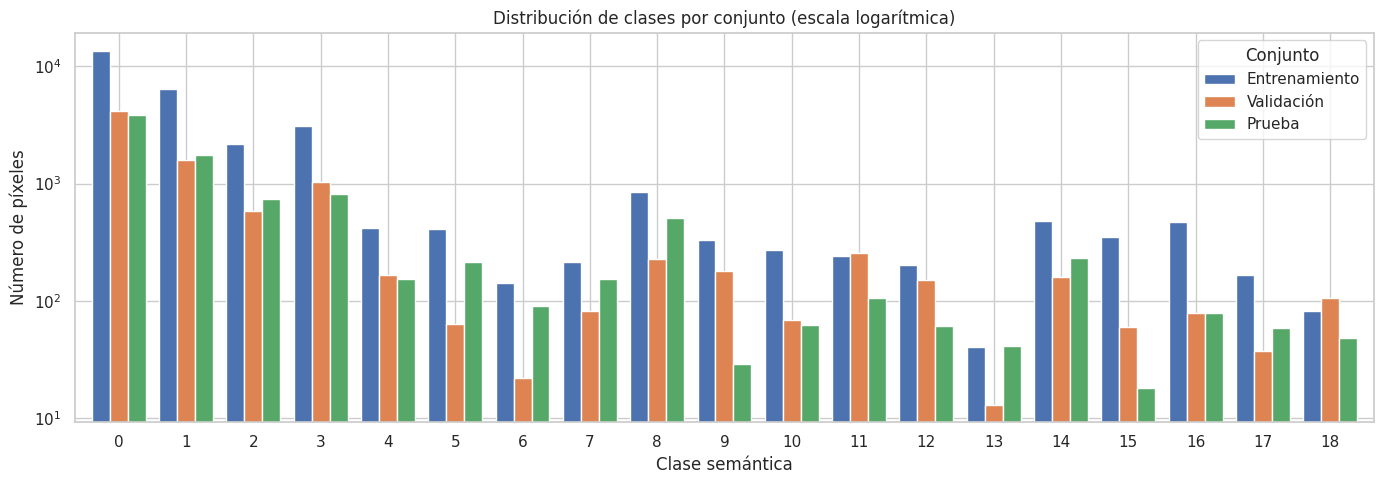

Clases ausentes en entrenamiento: []
Clases ausentes en validación: []
Clases ausentes en prueba: []
Razón de desbalance (clase mayoritaria / minoritaria) en entrenamiento: 342:1

Nota: se excluye Void (19). Las métricas macro utilizan las 19 clases válidas (0-18),
con valor 0 en las clases ausentes para mantener el criterio fijo entre modelos.


In [ ]:
# ==============================================================================
# 1.6 DISTRIBUCIÓN DE CLASES
# ==============================================================================

distribucion = pd.DataFrame({
    "Clase": CLASES,
    "Nombre": [NOMBRES_CLASES[c] for c in CLASES],
    "Entrenamiento": np.bincount(y_train.astype(int), minlength=19),
    "Validación": np.bincount(y_val.astype(int), minlength=19),
    "Prueba": np.bincount(y_test.astype(int), minlength=19),
})
distribucion["% Entrenamiento"] = (
    distribucion["Entrenamiento"] / len(y_train) * 100
).round(2)

print("=== DISTRIBUCIÓN DE CLASES (píxeles muestreados) ===")
display(distribucion)

ax = distribucion.set_index("Clase")[
    ["Entrenamiento", "Validación", "Prueba"]
].plot(kind="bar", figsize=(14, 5), width=0.8, logy=True)

plt.title("Distribución de clases por conjunto (escala logarítmica)")
plt.xlabel("Clase semántica")
plt.ylabel("Número de píxeles")
plt.xticks(rotation=0)
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()

ausentes_train = distribucion.loc[distribucion["Entrenamiento"] == 0, "Clase"].tolist()
ausentes_val = distribucion.loc[distribucion["Validación"] == 0, "Clase"].tolist()
ausentes_test = distribucion.loc[distribucion["Prueba"] == 0, "Clase"].tolist()

conteos_presentes = distribucion.loc[distribucion["Entrenamiento"] > 0, "Entrenamiento"]
razon_desbalance = conteos_presentes.max() / conteos_presentes.min()
print("Clases ausentes en entrenamiento:", ausentes_train)
print("Clases ausentes en validación:", ausentes_val)
print("Clases ausentes en prueba:", ausentes_test)
print(f"Razón de desbalance (clase mayoritaria / minoritaria) en entrenamiento: {razon_desbalance:.0f}:1")
print("\nNota: se excluye Void (19). Las métricas macro utilizan las 19 clases válidas (0-18),")
print("con valor 0 en las clases ausentes para mantener el criterio fijo entre modelos.")

## 2. Modelos Individuales de Referencia

En el Avance 4 se compararon siete algoritmos individuales. El **Análisis Discriminante Lineal (LDA)** obtuvo el mejor desempeño en validación después del ajuste de hiperparámetros, mientras que la **Red Neuronal Multicapa (MLP)** fue uno de los dos modelos seleccionados para la optimización final.

En esta etapa se recuperan sus configuraciones y se incorpora una **Regresión Logística** como alternativa lineal adicional. Estos tres algoritmos se entrenan bajo las mismas particiones y características para disponer de referencias consistentes y utilizarlos posteriormente en los ensambles heterogéneos.

**Métrica principal:** Macro F1, debido al desbalance entre clases agrícolas. También se reportan **Accuracy, Macro IoU y tiempo de entrenamiento**. La comparación principal se realiza en validación, utilizando las 19 clases válidas (0–18) y excluyendo la etiqueta Void. El conjunto de prueba se reserva hasta seleccionar el modelo final.

In [ ]:
# ==============================================================================
# 2.1 MÉTRICAS Y MODELOS INDIVIDUALES DE REFERENCIA
# ==============================================================================

def metricas(y_real, y_pred):
    """Métricas sobre las 19 clases válidas, con un conjunto fijo de etiquetas."""
    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)
    mask = (y_real >= 0) & (y_real != VOID_LABEL) & (y_real < 19)
    if not np.any(mask):
        raise ValueError("No hay píxeles válidos para evaluar")
    y_real, y_pred = y_real[mask], y_pred[mask]
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Macro F1": f1_score(
            y_real, y_pred, labels=CLASES, average="macro", zero_division=0
        ),
        "Macro IoU": jaccard_score(
            y_real, y_pred, labels=CLASES, average="macro", zero_division=0
        ),
    }

scorer_f1 = make_scorer(
    f1_score, labels=CLASES, average="macro", zero_division=0
)

# Los modelos se ajustan con la misma submuestra reproducible del conjunto
# de entrenamiento. Validación y prueba no intervienen en estos ajustes.
rng_fit = np.random.default_rng(SEED + 77)
indices_fit = rng_fit.choice(
    len(X_train),
    size=min(MAX_MUESTRAS_ENTRENAMIENTO, len(X_train)),
    replace=False
)
X_fit = X_train[indices_fit]
y_fit = y_train[indices_fit]
g_fit = g_train[indices_fit]
print(f"Entrenamiento compartido: {len(y_fit):,} píxeles de "
      f"{len(np.unique(g_fit))} parches")

# Hiperparámetros provenientes del Avance 4.
lda_av4 = Pipeline([
    ("scaler", RobustScaler()),
    ("clf", LinearDiscriminantAnalysis(solver="svd", tol=0.002487))
])

mlp_av4 = Pipeline([
    ("scaler", PowerTransformer(method="yeo-johnson")),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(256, 128, 64), activation="tanh",
        alpha=0.004676, learning_rate_init=0.0003823,
        batch_size=256, n_iter_no_change=8, max_iter=75,
        early_stopping=True, random_state=SEED
    ))
])

logreg_av4 = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=500,
        random_state=SEED, n_jobs=N_JOBS
    ))
])

individuales = {
    "LDA (mejor individual Avance 4)": lda_av4,
    "MLP (Avance 4)": mlp_av4,
    "Regresión Logística (Avance 4)": logreg_av4,
}

registros_ind = []
modelos_ind_entrenados = {}
for nombre, modelo in individuales.items():
    print(f"Ajustando {nombre}...", flush=True)
    t0 = time.time()
    modelo.fit(X_fit, y_fit)
    t_ent = time.time() - t0
    pred = modelo.predict(X_val)
    m = metricas(y_val, pred)
    registros_ind.append({"Modelo": nombre, **m, "Tiempo entrenamiento (s)": t_ent,
                          "Tipo": "Individual"})
    modelos_ind_entrenados[nombre] = modelo
    print(f"{nombre:38s} F1={m['Macro F1']:.4f} | IoU={m['Macro IoU']:.4f} | Acc={m['Accuracy']:.4f} | {t_ent:.1f}s")

Entrenamiento compartido: 15,000 píxeles de 100 parches
Ajustando LDA (mejor individual Avance 4)...
LDA (mejor individual Avance 4)        F1=0.3933 | IoU=0.2834 | Acc=0.6768 | 0.1s
Ajustando MLP (Avance 4)...
MLP (Avance 4)                         F1=0.3454 | IoU=0.2515 | Acc=0.6678 | 17.9s
Ajustando Regresión Logística (Avance 4)...
Regresión Logística (Avance 4)         F1=0.3018 | IoU=0.1998 | Acc=0.4521 | 5.0s


## 3. Construcción de Ensambles Homogéneos

Los ensambles homogéneos combinan varias instancias de un mismo tipo de algoritmo. En este caso se evalúan **Random Forest** y **Extra Trees**, dos métodos basados en árboles de decisión que introducen aleatoriedad de formas distintas:

| Modelo | Estrategia | Justificación |
|---|---|---|
| Random Forest | Bagging de árboles con selección aleatoria de características | Permite reducir la varianza de un árbol individual y constituye una referencia conocida desde el Avance 3. |
| Extra Trees | Conjunto de árboles con divisiones más aleatorias | Permite comprobar si una mayor aleatoriedad mejora la generalización de las predicciones. |

Para ambos modelos se aplica **`RandomizedSearchCV`** con cuatro configuraciones y validación cruzada **`GroupKFold`** de dos particiones, agrupando los píxeles por parche. Se optimizan el número de árboles, la profundidad máxima, el mínimo de muestras por hoja y la proporción de características consideradas en cada división.

La búsqueda se realiza con una submuestra del entrenamiento y la mejor configuración se vuelve a entrenar con la misma muestra de 15,000 píxeles que utilizan los modelos individuales (o menos en modo rápido). La selección de hiperparámetros se basa en **Macro F1**; el fold 4 permite contrastar su desempeño fuera de los parches empleados en la búsqueda.

In [ ]:
# ==============================================================================
# 3.1 OPTIMIZACIÓN DE ENSAMBLES HOMOGÉNEOS
# ==============================================================================
# Búsqueda acotada con CV por patch: 4 candidatos × 2 folds por algoritmo.
cv_group = GroupKFold(n_splits=2)
rng_opt = np.random.default_rng(SEED + 15)
idx_opt = rng_opt.choice(
    len(y_fit), size=min(MAX_MUESTRAS_BUSQUEDA, len(y_fit)), replace=False
)
X_opt, y_opt, grupos_opt = X_fit[idx_opt], y_fit[idx_opt], g_fit[idx_opt]

busquedas_homogeneas = {
    "Random Forest optimizado": (
        RandomForestClassifier(
            random_state=SEED, n_jobs=1, class_weight="balanced_subsample"
        ),
        {
            "n_estimators": [60, 100],
            "max_depth": [12, 18],
            "min_samples_leaf": [2, 4],
            "max_features": ["sqrt", 0.5],
        }
    ),
    "Extra Trees optimizado": (
        ExtraTreesClassifier(
            random_state=SEED, n_jobs=1, class_weight="balanced"
        ),
        {
            "n_estimators": [60, 100],
            "max_depth": [12, 18],
            "min_samples_leaf": [2, 4],
            "max_features": ["sqrt", 0.5],
        }
    ),
}

modelos_homogeneos = {}
registros_hom = []
for nombre, (base, espacio) in busquedas_homogeneas.items():
    print(f"\n=== {nombre} ===", flush=True)
    t0 = time.time()
    search = RandomizedSearchCV(
        estimator=base,
        param_distributions=espacio,
        n_iter=4,
        scoring=scorer_f1,
        cv=cv_group,
        random_state=SEED,
        n_jobs=2,
        pre_dispatch=2,
        verbose=2,
        refit=False
    )
    search.fit(X_opt, y_opt, groups=grupos_opt)
    print("Mejores hiperparámetros:", search.best_params_, flush=True)
    print(f"Macro F1 promedio de CV: {search.best_score_:.4f}", flush=True)

    # Se ajusta el mejor candidato sobre la misma muestra de entrenamiento
    # que se emplea en los modelos de referencia.
    mejor = clone(base).set_params(**search.best_params_, n_jobs=2)
    print("Ajustando mejor configuración...", flush=True)
    mejor.fit(X_fit, y_fit)
    t_ent = time.time() - t0
    pred = mejor.predict(X_val)
    m = metricas(y_val, pred)
    modelos_homogeneos[nombre] = mejor
    registros_hom.append({
        "Modelo": nombre, **m, "Tiempo entrenamiento (s)": t_ent,
        "Tipo": "Ensamble homogéneo"
    })
    print(f"Validación: F1={m['Macro F1']:.4f} | IoU={m['Macro IoU']:.4f} | "
          f"Accuracy={m['Accuracy']:.4f} | tiempo={t_ent:.1f}s", flush=True)


=== Random Forest optimizado ===
Fitting 2 folds for each of 4 candidates, totalling 8 fits
Mejores hiperparámetros: {'n_estimators': 60, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 18}
Macro F1 promedio de CV: 0.2010
Ajustando mejor configuración...
Validación: F1=0.2679 | IoU=0.1784 | Accuracy=0.5906 | tiempo=56.0s

=== Extra Trees optimizado ===
Fitting 2 folds for each of 4 candidates, totalling 8 fits
Mejores hiperparámetros: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 12}
Macro F1 promedio de CV: 0.1846
Ajustando mejor configuración...
Validación: F1=0.2703 | IoU=0.1758 | Accuracy=0.5211 | tiempo=7.7s


## 4. Construcción de Ensambles Heterogéneos

A diferencia de los ensambles homogéneos, los **heterogéneos** combinan algoritmos de distintas familias. La finalidad es aprovechar diferencias en la forma en que cada modelo representa y separa las clases de cultivo.

Se evalúan dos estrategias:

- **Voting (soft):** combina las probabilidades de LDA, MLP y Regresión Logística. Los pesos se establecen en 3, 2 y 1, respectivamente, dando mayor participación a los modelos con mejor referencia de desempeño en el Avance 4.
- **Stacking:** utiliza las probabilidades generadas por esos mismos tres clasificadores como entrada de un segundo nivel, implementado mediante Regresión Logística. La combinación se aprende con validación cruzada interna.

Los modelos base conservan el preprocesamiento y los hiperparámetros definidos para cada algoritmo. De esta forma se puede evaluar si **combinar modelos previamente estudiados** aporta una mejora frente a utilizar únicamente el mejor clasificador individual.

In [ ]:
# ==============================================================================
# 4.1 VOTING Y STACKING
# ==============================================================================
# Voting y Stacking reúnen los mejores individuales del Avance 4 (LDA y MLP)
# y una regresión logística para agregar diversidad de predicciones.
estimadores = [
    ("lda", clone(lda_av4)),
    ("mlp", clone(mlp_av4)),
    ("lr", clone(logreg_av4)),
]

voting = VotingClassifier(
    estimators=estimadores,
    voting="soft",
    weights=[3, 2, 1],
    n_jobs=1
)

# Stacking requiere volver a ajustar los modelos base en cada partición.
# Se utiliza un subconjunto menor y splits agrupados por patch para impedir
# que píxeles de un mismo patch entren y validen simultáneamente al meta-modelo.
rng_stack = np.random.default_rng(SEED + 18)
idx_stack = rng_stack.choice(
    len(y_fit), size=min(MAX_MUESTRAS_STACKING, len(y_fit)), replace=False
)
X_stack, y_stack, g_stack = X_fit[idx_stack], y_fit[idx_stack], g_fit[idx_stack]
cv_stacking = list(GroupKFold(n_splits=2).split(X_stack, y_stack, g_stack))

stacking = StackingClassifier(
    estimators=[
        ("lda", clone(lda_av4)),
        ("mlp", clone(mlp_av4)),
        ("lr", clone(logreg_av4)),
    ],
    final_estimator=LogisticRegression(
        C=1.0, max_iter=200, random_state=SEED
    ),
    stack_method="predict_proba",
    cv=cv_stacking,
    n_jobs=1,
    passthrough=False
)

heterogeneos = {
    "Voting heterogéneo (soft)": (voting, X_fit, y_fit),
    "Stacking heterogéneo": (stacking, X_stack, y_stack),
}

modelos_heterogeneos = {}
registros_het = []
for nombre, (modelo, X_ent, y_ent) in heterogeneos.items():
    print(f"\n=== {nombre} === ({len(y_ent):,} píxeles)", flush=True)
    t0 = time.time()
    modelo.fit(X_ent, y_ent)
    t_ent = time.time() - t0
    pred = modelo.predict(X_val)
    m = metricas(y_val, pred)
    modelos_heterogeneos[nombre] = modelo
    registros_het.append({
        "Modelo": nombre, **m, "Tiempo entrenamiento (s)": t_ent,
        "Tipo": "Ensamble heterogéneo"
    })
    print(f"Macro F1={m['Macro F1']:.4f} | Macro IoU={m['Macro IoU']:.4f} | "
          f"Accuracy={m['Accuracy']:.4f} | {t_ent:.1f}s", flush=True)


=== Voting heterogéneo (soft) === (15,000 píxeles)
Macro F1=0.4095 | Macro IoU=0.2974 | Accuracy=0.6922 | 20.9s

=== Stacking heterogéneo === (8,000 píxeles)
Macro F1=0.2761 | Macro IoU=0.2111 | Accuracy=0.6816 | 23.3s


## 5. Comparativa de Desempeño y Elección del Modelo Final

Se integran en una misma tabla los resultados del **LDA de referencia** y los cuatro ensambles: Random Forest, Extra Trees, Voting y Stacking. Las alternativas se ordenan por **Macro F1 en validación**, manteniendo como métricas complementarias **Accuracy, Macro IoU y tiempo de entrenamiento**.

La selección del modelo final sigue dos criterios:

1. **Desempeño:** se prioriza el mayor Macro F1 en validación para evitar que las clases mayoritarias definan por sí solas la elección.
2. **Criterio de desempate:** ante valores iguales de Macro F1, se utiliza Macro IoU, que mide la superposición entre las clases reales y las predichas.

El conjunto de prueba **no participa en esta selección**. Se utiliza únicamente después de definir el modelo final, manteniendo la separación entre ajuste y evaluación independiente.

In [ ]:
# ==============================================================================
# 5.1 TABLA COMPARATIVA Y SELECCIÓN
# ==============================================================================
# Para la tabla obligatoria se conserva el mejor individual y los 4 ensambles.
df_ind = pd.DataFrame(registros_ind)
df_hom = pd.DataFrame(registros_hom)
df_het = pd.DataFrame(registros_het)

df_comparativa = pd.concat([
    df_ind[df_ind["Modelo"] == "LDA (mejor individual Avance 4)"],
    df_hom, df_het
], ignore_index=True).sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(df_comparativa.style.format({
    "Accuracy": "{:.4f}", "Macro F1": "{:.4f}", "Macro IoU": "{:.4f}",
    "Tiempo entrenamiento (s)": "{:.1f}"
}))

# Selección por la métrica principal; desempate por Macro IoU.
orden = df_comparativa.sort_values(["Macro F1", "Macro IoU"], ascending=False)
modelo_final_nombre = orden.iloc[0]["Modelo"]

todos_modelos = {**modelos_ind_entrenados, **modelos_homogeneos, **modelos_heterogeneos}
modelo_final = todos_modelos[modelo_final_nombre]

print("\nMODELO FINAL SELECCIONADO:", modelo_final_nombre)
print("Criterio: mayor Macro F1 en validación; Macro IoU como desempate.")


,Modelo,Accuracy,Macro F1,Macro IoU,Tiempo entrenamiento (s),Tipo
0,Voting heterogéneo (soft),0.6922,0.4095,0.2974,20.9,Ensamble heterogéneo
1,LDA (mejor individual Avance 4),0.6768,0.3933,0.2834,0.1,Individual
2,Stacking heterogéneo,0.6816,0.2761,0.2111,23.3,Ensamble heterogéneo
3,Extra Trees optimizado,0.5211,0.2703,0.1758,7.7,Ensamble homogéneo
4,Random Forest optimizado,0.5906,0.2679,0.1784,56.0,Ensamble homogéneo



MODELO FINAL SELECCIONADO: Voting heterogéneo (soft)
Criterio: mayor Macro F1 en validación; Macro IoU como desempate.


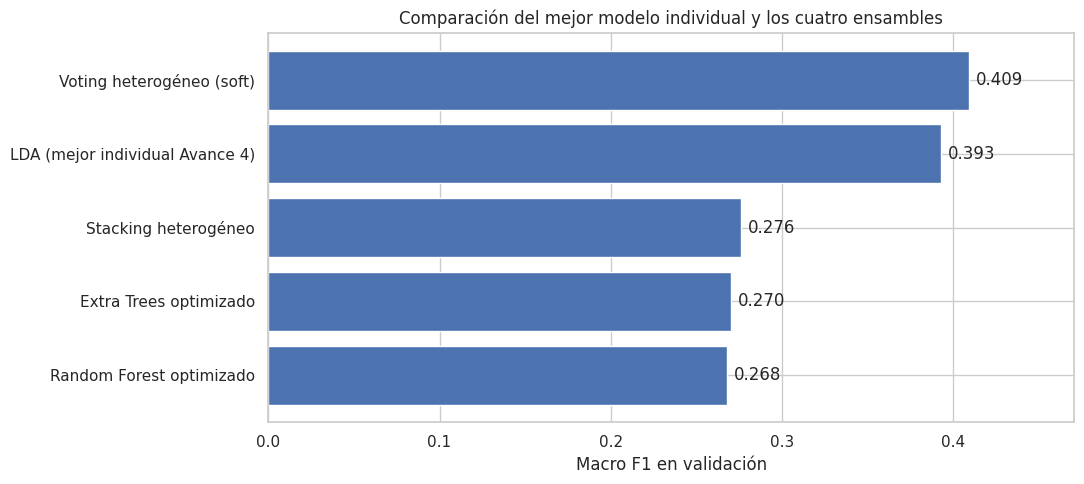

In [ ]:
# ==============================================================================
# 5.2 GRÁFICO 1 — COMPARACIÓN DE MODELOS
# ==============================================================================
plt.figure(figsize=(11, 5))
orden_plot = df_comparativa.sort_values("Macro F1", ascending=True)
plt.barh(orden_plot["Modelo"], orden_plot["Macro F1"])
plt.xlabel("Macro F1 en validación")
plt.title("Comparación del mejor modelo individual y los cuatro ensambles")
plt.xlim(0, max(0.45, orden_plot["Macro F1"].max() * 1.15))
for i, v in enumerate(orden_plot["Macro F1"]):
    plt.text(v + .004, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()



### 5.2 Interpretación de la Comparativa de Modelos

Los resultados de validación muestran que el ensamble **Voting heterogéneo (soft)** obtuvo el mejor desempeño, con un Macro F1 de **0.4095**, superando al LDA, que alcanzó **0.3933**. Aunque la diferencia es moderada, el resultado indica que combinar las probabilidades de distintos clasificadores permitió mejorar la identificación de las clases de cultivo en la muestra evaluada.

Por otra parte, Stacking obtuvo un Macro F1 de 0.2761, mientras que Random Forest y Extra Trees presentaron resultados inferiores a los del LDA. Esto muestra que utilizar ensambles no garantiza una mejora automática, ya que su desempeño depende tanto de los modelos que se combinan como de la estrategia utilizada para integrarlos.

La comparación también considera Accuracy, Macro IoU y los tiempos de entrenamiento, aspectos importantes para determinar si la mejora obtenida justifica una mayor complejidad computacional.

Con base en estos resultados, se seleccionó **Voting heterogéneo (soft)** como modelo final, utilizando exclusivamente el conjunto de validación para tomar esta decisión. Su desempeño sobre datos no vistos se analiza en la siguiente sección.


## 6. Evaluación del Modelo Seleccionado en Datos No Vistos

La selección del ganador se realiza con el fold 4. Después se evalúa en los píxeles muestreados del **fold 5**, que no se emplearon para entrenar o elegir hiperparámetros. Se presentan Accuracy, Macro F1, Macro IoU y resultados por clase, sin incluir los píxeles marcados como Void.

Como verificación adicional, se calculan las métricas del **LDA y Voting sobre exactamente los mismos píxeles de prueba**. La diferencia se acompaña de un intervalo descriptivo obtenido al remuestrear patches completos. Esta comparación permite valorar el tamaño de la mejora observada, pero no se utiliza para volver a seleccionar el modelo.

In [ ]:
# ==============================================================================
# 6.1 MÉTRICAS FINALES EN PRUEBA Y CONTRASTE LDA / VOTING
# ==============================================================================
# La elección del ganador ya se realizó con validación (sección 5.1).
# La prueba se utiliza ahora únicamente para evaluar y contrastar, no para
# cambiar retrospectivamente el modelo seleccionado.

t0 = time.time()
pred_test = modelo_final.predict(X_test)
tiempo_pred_test = time.time() - t0
met_test = metricas(y_test, pred_test)

print("=== MODELO SELECCIONADO — FOLD 5 (DATOS NO VISTOS) ===")
print("Modelo:", modelo_final_nombre)
for k, v in met_test.items():
    print(f"{k:10s}: {v:.4f}")
print(f"Tiempo de predicción: {tiempo_pred_test:.3f} s para {len(y_test):,} píxeles")

reporte_test = pd.DataFrame(classification_report(
    y_test, pred_test, labels=CLASES,
    target_names=[NOMBRES_CLASES[c] for c in CLASES],
    output_dict=True, zero_division=0
)).T
display(reporte_test.round(4))

# Contraste diagnóstico de las dos alternativas con mejores resultados previos.
# Se evalúan exactamente los mismos píxeles de prueba y las mismas etiquetas.
lda_referencia = modelos_ind_entrenados["LDA (mejor individual Avance 4)"]
voting_referencia = modelos_heterogeneos["Voting heterogéneo (soft)"]
pred_lda_test = lda_referencia.predict(X_test)
pred_voting_test = voting_referencia.predict(X_test)
m_lda_test = metricas(y_test, pred_lda_test)
m_voting_test = metricas(y_test, pred_voting_test)

df_contraste_test = pd.DataFrame([
    {"Modelo": "LDA", **m_lda_test},
    {"Modelo": "Voting heterogéneo (soft)", **m_voting_test}
])
print("\n=== COMPARACIÓN DIAGNÓSTICA LDA VS. VOTING (MISMO FOLD 5) ===")
display(df_contraste_test.round(4))
delta_voting_lda = m_voting_test["Macro F1"] - m_lda_test["Macro F1"]
print(f"Diferencia Voting − LDA en Macro F1: {delta_voting_lda:+.4f}")

# Intervalo descriptivo pareado por patch. Se remuestrean patches completos,
# no píxeles individuales, para respetar su dependencia espacial.
rng_boot = np.random.default_rng(SEED + 501)
patches_prueba = np.unique(g_test)
indices_por_patch = {pid: np.flatnonzero(g_test == pid) for pid in patches_prueba}
deltas_bootstrap = []
for _ in range(200):
    muestra_patches = rng_boot.choice(
        patches_prueba, size=len(patches_prueba), replace=True
    )
    ix = np.concatenate([indices_por_patch[p] for p in muestra_patches])
    f1_v = metricas(y_test[ix], pred_voting_test[ix])["Macro F1"]
    f1_l = metricas(y_test[ix], pred_lda_test[ix])["Macro F1"]
    deltas_bootstrap.append(f1_v - f1_l)
lim_inf, lim_sup = np.percentile(deltas_bootstrap, [2.5, 97.5])
print(f"Intervalo descriptivo bootstrap pareado (95%): [{lim_inf:+.4f}, {lim_sup:+.4f}]")
print("Comparación exploratoria por patch; no se utiliza para escoger el ganador.")

=== MODELO SELECCIONADO — FOLD 5 (DATOS NO VISTOS) ===
Modelo: Voting heterogéneo (soft)
Accuracy  : 0.6763
Macro F1  : 0.3447
Macro IoU : 0.2513
Tiempo de predicción: 0.115 s para 9,000 píxeles


,precision,recall,f1-score,support
Fondo,0.7503,0.7886,0.7690,3841.0000
Pradera,0.7764,0.7159,0.7449,1746.0000
Trigo blando de invierno,0.6393,0.8360,0.7245,744.0000
Maíz,0.9273,0.6227,0.7451,819.0000
Cebada de invierno,0.1607,0.1169,0.1353,154.0000
Colza de invierno,0.8744,0.8169,0.8447,213.0000
Cebada de primavera,0.0000,0.0000,0.0000,91.0000
Girasol,0.2935,0.1776,0.2213,152.0000
Vid,0.4470,0.5000,0.4720,506.0000
Remolacha,0.3108,0.7931,0.4466,29.0000



=== COMPARACIÓN DIAGNÓSTICA LDA VS. VOTING (MISMO FOLD 5) ===


,Modelo,Accuracy,Macro F1,Macro IoU
0,LDA,0.6554,0.3275,0.2394
1,Voting heterogéneo (soft),0.6763,0.3447,0.2513


Diferencia Voting − LDA en Macro F1: +0.0171
Intervalo descriptivo bootstrap pareado (95%): [+0.0060, +0.0282]
Comparación exploratoria por patch; no se utiliza para escoger el ganador.


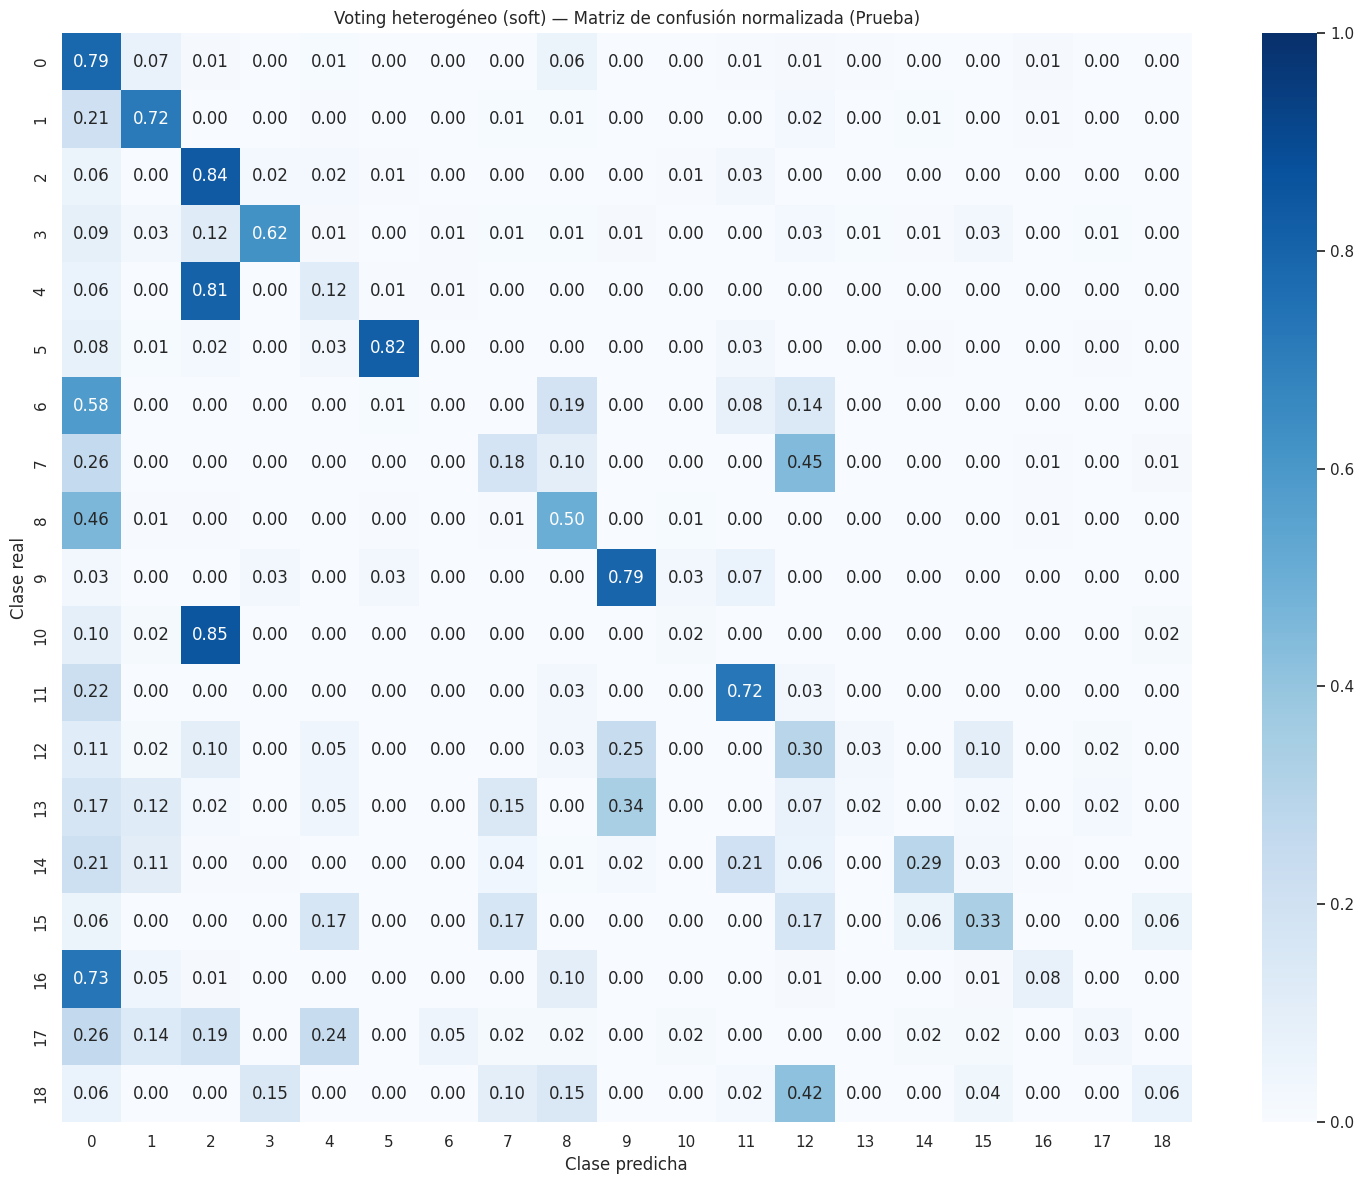

In [ ]:
# ==============================================================================
# 6.2 GRÁFICO 2 — MATRIZ DE CONFUSIÓN NORMALIZADA
# ==============================================================================
cm = confusion_matrix(y_test, pred_test, labels=CLASES, normalize="true")
plt.figure(figsize=(15, 12))
sns.heatmap(cm, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            xticklabels=CLASES, yticklabels=CLASES)
plt.xlabel("Clase predicha"); plt.ylabel("Clase real")
plt.title(f"{modelo_final_nombre} — Matriz de confusión normalizada (Prueba)")
plt.tight_layout(); plt.show()


### 6.2 Interpretación de la Matriz de Confusión

La matriz está normalizada por clase real: la diagonal indica el porcentaje de píxeles correctamente clasificados y las otras celdas muestran las confusiones más frecuentes. Se presentan las **19 clases evaluables de PASTIS**, incluido Fondo y excluida la etiqueta Void.

Esta representación permite observar dificultades que pueden quedar ocultas en Accuracy, especialmente en las clases agrícolas menos frecuentes.

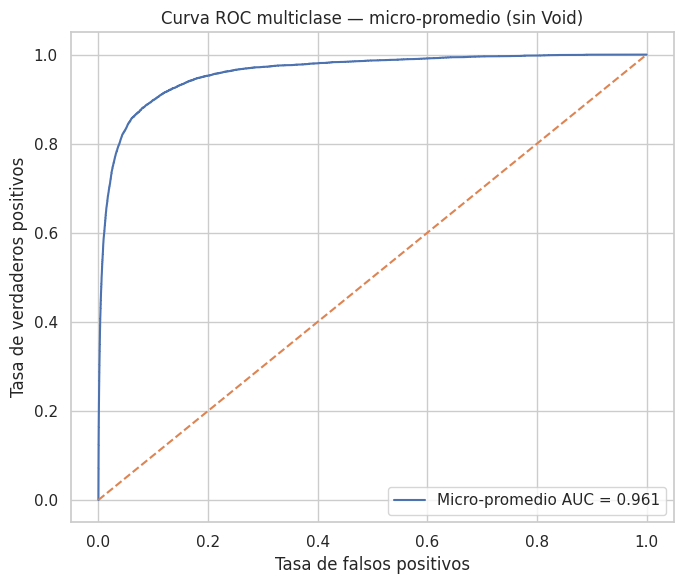

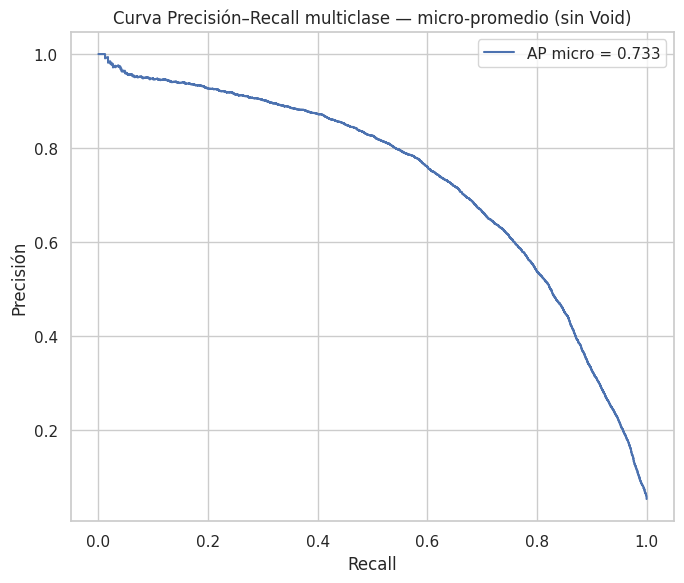

In [ ]:
# ==============================================================================
# 6.3 GRÁFICOS 3 Y 4 — ROC Y PRECISIÓN-RECALL MULTICLASE
# ==============================================================================
# Obtener probabilidades. Todos los candidatos definidos en este notebook soportan predict_proba.
proba_test = modelo_final.predict_proba(X_test)
clases_modelo = np.asarray(modelo_final.classes_)
# Las columnas de probabilidad se corresponden explícitamente con classes_.
# label_binarize cambia de forma en problemas binarios; esta representación
# mantiene una columna por clase del modelo.
y_bin = np.column_stack([(y_test == c).astype(int) for c in clases_modelo])

# Curvas micro-promedio: resumen global one-vs-rest.
fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), proba_test.ravel())
auc_micro = auc(fpr_micro, tpr_micro)

plt.figure(figsize=(7, 6))
plt.plot(fpr_micro, tpr_micro, label=f"Micro-promedio AUC = {auc_micro:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC multiclase — micro-promedio (sin Void)")
plt.legend(); plt.tight_layout(); plt.show()

precision_micro, recall_micro, _ = precision_recall_curve(y_bin.ravel(), proba_test.ravel())
ap_micro = average_precision_score(y_bin, proba_test, average="micro")
plt.figure(figsize=(7, 6))
plt.plot(recall_micro, precision_micro, label=f"AP micro = {ap_micro:.3f}")
plt.xlabel("Recall"); plt.ylabel("Precisión")
plt.title("Curva Precisión–Recall multiclase — micro-promedio (sin Void)")
plt.legend(); plt.tight_layout(); plt.show()

### 6.3 Interpretación de las Curvas ROC y Precisión–Recall

La curva ROC representa la relación entre verdaderos y falsos positivos a diferentes umbrales, mientras que la curva de Precisión–Recall muestra el compromiso entre recuperar ejemplos positivos y limitar falsas alarmas. Ambas se calculan con probabilidades del modelo sobre píxeles válidos del conjunto de prueba.

Se utiliza un **micro-promedio multiclase**, que resume todos los pares clase-píxel y se encuentra influido por las clases con mayor frecuencia. Por esa razón, estas curvas complementan —pero no sustituyen— Macro F1, Macro IoU y el reporte por clase.

,Característica,Caída Macro F1,Desviación
5,media_B7,0.3392,0.0103
4,media_B6,0.3320,0.0011
17,std_B6,0.3045,0.0005
16,std_B5,0.2869,0.0138
1,media_B3,0.2844,0.0037
18,std_B7,0.2833,0.0252
7,media_B8A,0.2741,0.0114
3,media_B5,0.2717,0.0028
20,std_B8A,0.2495,0.0001
13,std_B2,0.2288,0.0027


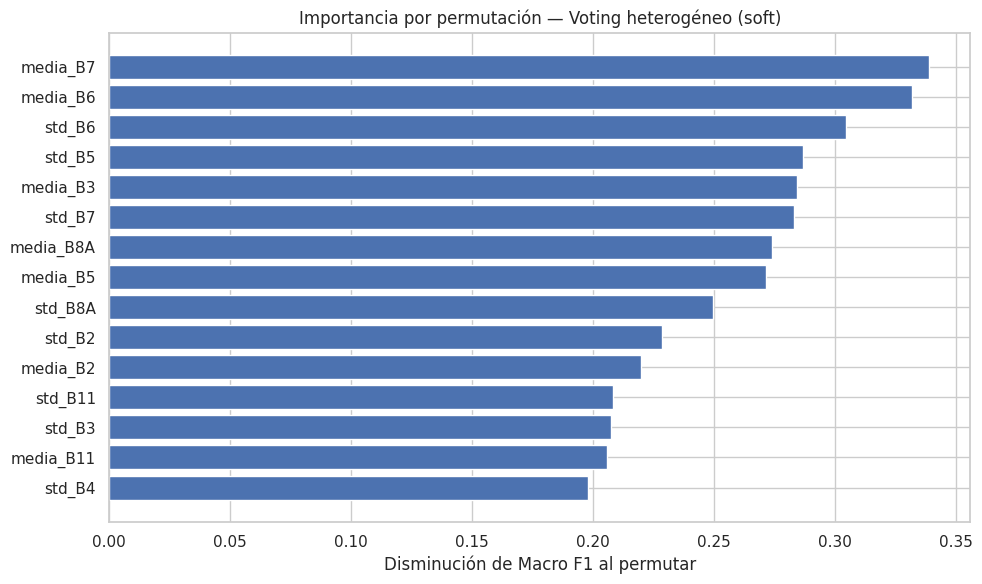

In [ ]:
# ==============================================================================
# 6.4 GRÁFICO 5 — IMPORTANCIA POR PERMUTACIÓN DEL MODELO FINAL
# ==============================================================================
g_imp = np.random.default_rng(SEED)
idx_imp = g_imp.choice(len(X_val), size=min(800, len(X_val)), replace=False)
imp = permutation_importance(
    modelo_final, X_val[idx_imp], y_val[idx_imp],
    scoring=scorer_f1, n_repeats=2, random_state=SEED, n_jobs=1
)
df_imp = pd.DataFrame({
    "Característica": nombres_features,
    "Caída Macro F1": imp.importances_mean,
    "Desviación": imp.importances_std
}).sort_values("Caída Macro F1", ascending=False)

display(df_imp.head(15).round(4))
plt.figure(figsize=(10, 6))
top15 = df_imp.head(15).sort_values("Caída Macro F1")
plt.barh(top15["Característica"], top15["Caída Macro F1"])
plt.xlabel("Disminución de Macro F1 al permutar")
plt.title(f"Importancia por permutación — {modelo_final_nombre}")
plt.tight_layout(); plt.show()


### 6.4 Interpretación de la Importancia de Características

La importancia por permutación estima cuánto disminuye el **Macro F1** cuando se altera una característica y se mantienen las demás. Una caída mayor indica que el modelo depende en mayor medida de esa variable para realizar sus predicciones.

Este análisis permite revisar qué bandas e índices, junto con sus estadísticas temporales, aportan más información al modelo final. Debe distinguirse de la matriz de confusión: mientras esta última describe **errores entre clases**, la importancia por permutación evalúa la **contribución de las variables de entrada** al desempeño del clasificador.

## 7. Conclusiones Metodológicas CRISP-ML(Q)

### Resultados principales

Se compararon dos ensambles homogéneos (**Random Forest y Extra Trees**) y dos heterogéneos (**Voting y Stacking**) con el LDA que destacó en el Avance 4. Los modelos utilizan las mismas características, las mismas particiones y un criterio de selección común: **Macro F1 de validación**. La comparación también incorpora Accuracy, Macro IoU y tiempo de entrenamiento.

La evaluación se realizó sobre una **muestra reproducible de patches de PASTIS**, no sobre la totalidad del conjunto. La etiqueta Void (19) se excluyó de los clasificadores y las métricas, y las clases válidas se evaluaron con un conjunto fijo de etiquetas (0–18). El modelo final fue elegido con el fold 4; el fold 5 se utilizó únicamente después de fijar esa decisión.

### Criterios de evaluación

El desbalance de clases hace necesario observar métricas macro, ya que un Accuracy elevado puede ocultar problemas en cultivos minoritarios. También se consideró el tiempo de entrenamiento para determinar si el desempeño adicional de un ensamble justifica su complejidad. La matriz de confusión, las curvas ROC y Precisión–Recall y la importancia por permutación permiten revisar los resultados desde perspectivas complementarias.

### Limitaciones del enfoque

Los clasificadores empleados trabajan sobre **estadísticas temporales por píxel**. No utilizan directamente la geometría de las parcelas ni la secuencia satelital completa. Por ello, sus resultados sirven como referencia experimental, pero no se interpretan como equivalentes a la evaluación de un modelo de segmentación espacio-temporal como TSViT. El efecto del desbalance y las confusiones entre cultivos debe considerarse al analizar la calidad de las predicciones.

La siguiente celda presenta una síntesis cuantitativa calculada con los resultados de esta misma ejecución. Se incluye la comparación pareada entre LDA y Voting en prueba para distinguir una mejora observada de una ventaja que podría deberse a la variabilidad de la muestra.

In [ ]:
# ==============================================================================
# 7.1 SÍNTESIS CUANTITATIVA DE LOS RESULTADOS
# ==============================================================================
f1_lda_val = float(df_comparativa.loc[
    df_comparativa['Modelo'] == 'LDA (mejor individual Avance 4)', 'Macro F1'
].iloc[0])
f1_win_val = float(orden.iloc[0]['Macro F1'])
delta_val = f1_win_val - f1_lda_val
interpretacion_delta = (
    'La diferencia es pequeña y debe interpretarse con cautela.'
    if abs(delta_val) < 0.01 else
    'La diferencia es apreciable en esta muestra de validación.'
)
msg_contraste = (
    'El intervalo incluye el cero, por lo que el contraste por patches no permite '
    'afirmar una ventaja consistente entre ambos métodos en esta muestra.'
    if lim_inf <= 0 <= lim_sup else
    'El intervalo no incluye el cero, aunque la estimación sigue limitada al '
    'número de patches evaluados.'
)

texto = f"""
**Síntesis de esta ejecución.** En validación, el modelo con mejor Macro F1 fue
**{modelo_final_nombre}** ({f1_win_val:.4f}), frente a {f1_lda_val:.4f} del LDA.
La diferencia fue de **{delta_val:+.4f}**. {interpretacion_delta}

En prueba, el modelo seleccionado obtuvo **Macro F1 = {met_test['Macro F1']:.4f}**,
**Macro IoU = {met_test['Macro IoU']:.4f}** y
**Accuracy = {met_test['Accuracy']:.4f}** sobre {len(y_test):,} píxeles válidos.

En el contraste LDA–Voting, ambos evaluados sobre exactamente los mismos
píxeles del fold 5, la diferencia en Macro F1 (Voting − LDA) fue
**{delta_voting_lda:+.4f}** y su intervalo descriptivo por remuestreo de patches
fue **[{lim_inf:+.4f}, {lim_sup:+.4f}]**. {msg_contraste}

Los resultados proceden de {len(np.unique(g_train))} patches de entrenamiento,
{len(np.unique(g_val))} de validación y {len(np.unique(g_test))} de prueba,
por lo que representan una evaluación muestreada de PASTIS.
"""
display(Markdown(texto))


**Síntesis de esta ejecución.** En validación, el modelo con mejor Macro F1 fue
**Voting heterogéneo (soft)** (0.4095), frente a 0.3933 del LDA.
La diferencia fue de **+0.0162**. La diferencia es apreciable en esta muestra de validación.

En prueba, el modelo seleccionado obtuvo **Macro F1 = 0.3447**,
**Macro IoU = 0.2513** y
**Accuracy = 0.6763** sobre 9,000 píxeles válidos.

En el contraste LDA–Voting, ambos evaluados sobre exactamente los mismos
píxeles del fold 5, la diferencia en Macro F1 (Voting − LDA) fue
**+0.0171** y su intervalo descriptivo por remuestreo de patches
fue **[+0.0060, +0.0282]**. El intervalo no incluye el cero, aunque la estimación sigue limitada al número de patches evaluados.

Los resultados proceden de 100 patches de entrenamiento,
30 de validación y 30 de prueba,
por lo que representan una evaluación muestreada de PASTIS.


# EXTRA. Pruebas Exploratorias con U-Net y Descripciones Fenológicas

Como complemento a los cuatro ensambles se realizaron dos pruebas de menor escala. La primera utiliza una **U-Net** para incorporar el contexto espacial de los píxeles. La segunda utiliza un **modelo de lenguaje** para describir curvas temporales NDVI y comparar sus textos con los perfiles de algunos cultivos.

Estos ejercicios tienen un tamaño de muestra y una finalidad diferentes de la comparación principal. Sus métricas se presentan por separado y no intervienen en la elección del modelo final.

## E1. Comparación de Cinco Características

La importancia por permutación del LDA en el Avance 4 destacó `media_B7`, `media_B6`, `std_B7`, `std_B6` y `media_B3`. Para medir el efecto de reducir variables, se compara un LDA con las **52 características** y otro con esas **cinco características**, entrenados con **exactamente los mismos píxeles** y evaluados sobre la misma partición de validación.

In [ ]:
# ==============================================================================
# E1.1 COMPARACIÓN CONTROLADA: 52 VS. 5 CARACTERÍSTICAS
# ==============================================================================
TOP5_AVANCE4 = ["media_B7", "media_B6", "std_B7", "std_B6", "media_B3"]
idx_top5 = [nombres_features.index(c) for c in TOP5_AVANCE4]

# Ambos LDA usan EXACTAMENTE X_fit / y_fit (mismos patches, píxeles y etiquetas).
lda_52 = modelos_ind_entrenados["LDA (mejor individual Avance 4)"]
lda_5 = clone(lda_av4)

inicio_5 = time.time()
lda_5.fit(X_fit[:, idx_top5], y_fit)
tiempo_5 = time.time() - inicio_5

pred52 = lda_52.predict(X_val)
pred5 = lda_5.predict(X_val[:, idx_top5])
m52 = metricas(y_val, pred52)
m5 = metricas(y_val, pred5)

comparacion_5_52 = pd.DataFrame([
    {"Representación": "52 características", **m52},
    {"Representación": "Top 5 Avance 4", **m5}
])
print(f"Muestra idéntica: {len(y_fit):,} píxeles de entrenamiento")
print("Mismas muestras de validación:", len(y_val))
display(comparacion_5_52.round(4))
print(f"Tiempo de entrenamiento LDA Top-5: {tiempo_5:.2f} s")
print(f"Cambio en Macro F1 (5 − 52): {m5['Macro F1'] - m52['Macro F1']:+.4f}")

Muestra idéntica: 15,000 píxeles de entrenamiento
Mismas muestras de validación: 9000


,Representación,Accuracy,Macro F1,Macro IoU
0,52 características,0.6768,0.3933,0.2834
1,Top 5 Avance 4,0.5432,0.1735,0.1146


Tiempo de entrenamiento LDA Top-5: 0.01 s
Cambio en Macro F1 (5 − 52): -0.2197


## E2. Prueba de Segmentación con U-Net

U-Net es una red neuronal convolucional que genera una etiqueta para cada píxel de una imagen y puede aprovechar la información de sus vecinos. En esta prueba se construyen cinco mapas espaciales por patch a partir de las características seleccionadas en el Avance 4.

Se utiliza una red pequeña y una muestra reducida de patches (16 de entrenamiento, cuatro de validación y cuatro de prueba). Los cinco canales se normalizan utilizando únicamente estadísticas de entrenamiento. Además, la etiqueta Void se omite al calcular la pérdida y las métricas para mantener la misma definición de clases válidas que en el análisis principal.

Se registran la pérdida de entrenamiento, Macro F1 y Macro IoU durante seis épocas, además del desempeño final sobre los patches de prueba. Se trata de una comprobación inicial de la arquitectura, no de una comparación directa con los ensambles entrenados sobre otros tamaños de muestra.

In [ ]:
# ==============================================================================
# E2.1 PREPARACIÓN DE MAPAS ESPACIALES TOP-5 PARA U-NET
# ==============================================================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("Dispositivo para U-Net:", DEVICE)

# Cantidades deliberadamente pequeñas: prueba complementaria de segmentación.
N_UNET = {"train": 16, "val": 4, "test": 4}

def mapas_top5(img):
    x = np.maximum(img.astype(np.float32) / 10000.0, 0.0)
    # índices Sentinel-2 en el tensor PASTIS: B3=1, B6=4, B7=5
    mapas = np.stack([
        x[:, 5].mean(axis=0),  # media_B7
        x[:, 4].mean(axis=0),  # media_B6
        x[:, 5].std(axis=0),   # std_B7
        x[:, 4].std(axis=0),   # std_B6
        x[:, 1].mean(axis=0),  # media_B3
    ], axis=0)
    return mapas.astype(np.float32)

def cargar_patch_unet(pid):
    img = np.load(ruta_pastis(f"DATA_S2/S2_{pid}.npy"))
    target = np.load(ruta_pastis(f"ANNOTATIONS/TARGET_{pid}.npy"))[0].astype(np.int64)
    return mapas_top5(img), target

ids_unet = {
    "train": ids_elegidos["train"][:N_UNET["train"]],
    "val": ids_elegidos["val"][:N_UNET["val"]],
    "test": ids_elegidos["test"][:N_UNET["test"]],
}

class PASTISTop5Dataset(Dataset):
    def __init__(self, ids):
        self.muestras = [cargar_patch_unet(pid) for pid in ids]
    def __len__(self): return len(self.muestras)
    def __getitem__(self, i):
        x, y = self.muestras[i]
        x_norm = (x - mu_unet) / sigma_unet
        return torch.from_numpy(x_norm.astype(np.float32)), torch.from_numpy(y)

# Las cinco bandas se normalizan con el entrenamiento exclusivamente.
# No se utilizan estadísticas de los patches de validación o prueba.
array_unet_train = np.stack([
    cargar_patch_unet(pid)[0] for pid in ids_unet["train"]
], axis=0)
mu_unet = array_unet_train.mean(axis=(0, 2, 3), keepdims=True)[0]
sigma_unet = array_unet_train.std(axis=(0, 2, 3), keepdims=True)[0]
sigma_unet = np.maximum(sigma_unet, 1e-4)
del array_unet_train

train_loader = DataLoader(PASTISTop5Dataset(ids_unet["train"]), batch_size=2, shuffle=True)
val_loader = DataLoader(PASTISTop5Dataset(ids_unet["val"]), batch_size=1, shuffle=False)
test_loader = DataLoader(PASTISTop5Dataset(ids_unet["test"]), batch_size=1, shuffle=False)
print("Patches U-Net:", {k:len(v) for k,v in ids_unet.items()})
print("Canales normalizados con entrenamiento exclusivamente.")

Dispositivo para U-Net: cuda
Patches U-Net: {'train': 16, 'val': 4, 'test': 4}
Canales normalizados con entrenamiento exclusivamente.


In [ ]:
# ==============================================================================
# E2.2 MINI U-NET
# ==============================================================================
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()
        )
    def forward(self, x): return self.net(x)

class MiniUNet(nn.Module):
    def __init__(self, in_ch=5, n_classes=19):
        super().__init__()
        self.e1=DoubleConv(in_ch,32); self.p1=nn.MaxPool2d(2)
        self.e2=DoubleConv(32,64); self.p2=nn.MaxPool2d(2)
        self.b=DoubleConv(64,128)
        self.u2=nn.ConvTranspose2d(128,64,2,2); self.d2=DoubleConv(128,64)
        self.u1=nn.ConvTranspose2d(64,32,2,2); self.d1=DoubleConv(64,32)
        self.out=nn.Conv2d(32,n_classes,1)
    def forward(self,x):
        e1=self.e1(x); e2=self.e2(self.p1(e1)); b=self.b(self.p2(e2))
        d2=self.d2(torch.cat([self.u2(b),e2],1))
        d1=self.d1(torch.cat([self.u1(d2),e1],1))
        return self.out(d1)

unet = MiniUNet().to(DEVICE)
optimizer = torch.optim.AdamW(unet.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=VOID_LABEL)
print(f"Parámetros entrenables: {sum(p.numel() for p in unet.parameters() if p.requires_grad):,}")

Parámetros entrenables: 468,979


Epoch 01 | loss=2.8174 | val F1=0.0049 | val IoU=0.0025
Epoch 02 | loss=2.4669 | val F1=0.0561 | val IoU=0.0361
Epoch 03 | loss=2.2797 | val F1=0.0709 | val IoU=0.0468
Epoch 04 | loss=2.1081 | val F1=0.0827 | val IoU=0.0548
Epoch 05 | loss=2.0217 | val F1=0.0915 | val IoU=0.0610
Epoch 06 | loss=1.9159 | val F1=0.0910 | val IoU=0.0610

=== U-NET EXPLORATORIA — PRUEBA ===
{'Accuracy': 0.46452797470291224, 'Macro F1': 0.09496523822412435, 'Macro IoU': np.float64(0.06643281004945373)}


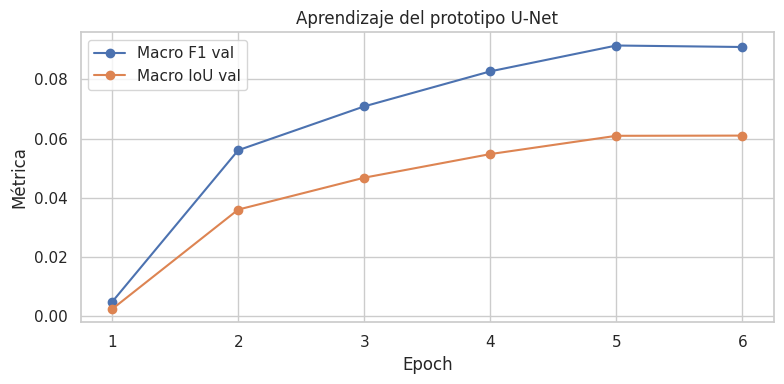

In [ ]:
# ==============================================================================
# E2.3 ENTRENAMIENTO Y EVALUACIÓN EXPLORATORIA
# ==============================================================================
def evaluar_unet(loader):
    unet.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for xb,yb in loader:
            logits=unet(xb.to(DEVICE)); pred=logits.argmax(1).cpu().numpy()
            verdad = yb.numpy().ravel()
            estimado = pred.ravel()
            validos = (verdad != VOID_LABEL) & (verdad >= 0) & (verdad < 19)
            ys.append(verdad[validos]); ps.append(estimado[validos])
    y=np.concatenate(ys); p=np.concatenate(ps)
    return metricas(y,p), y,p

hist=[]
EPOCHS=6
for ep in range(1,EPOCHS+1):
    unet.train(); losses=[]
    for xb,yb in train_loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        optimizer.zero_grad(); loss=criterion(unet(xb),yb); loss.backward(); optimizer.step()
        losses.append(loss.item())
    mv,_,_=evaluar_unet(val_loader)
    hist.append({"epoch":ep,"loss":np.mean(losses),**mv})
    print(f"Epoch {ep:02d} | loss={np.mean(losses):.4f} | val F1={mv['Macro F1']:.4f} | val IoU={mv['Macro IoU']:.4f}")

m_unet_test, y_unet_test, p_unet_test = evaluar_unet(test_loader)
print("\n=== U-NET EXPLORATORIA — PRUEBA ===")
print(m_unet_test)

h=pd.DataFrame(hist)
plt.figure(figsize=(8,4)); plt.plot(h.epoch,h["Macro F1"],marker="o",label="Macro F1 val")
plt.plot(h.epoch,h["Macro IoU"],marker="o",label="Macro IoU val")
plt.xlabel("Epoch"); plt.ylabel("Métrica"); plt.title("Aprendizaje del prototipo U-Net"); plt.legend(); plt.tight_layout(); plt.show()

## E3. Prueba con Modelo de Lenguaje y Descripciones Fenológicas

El artículo *“Phenology description is all you need!”* (Wen et al., 2025) estudia la relación entre series de observaciones satelitales y descripciones del desarrollo de los cultivos. Como aproximación sencilla a esa idea, aquí se construyen curvas NDVI de cuatro clases agrícolas presentes en PASTIS y se utiliza un modelo de lenguaje para describir su comportamiento.

Los perfiles de referencia se obtienen únicamente de patches de entrenamiento. Después, el modelo de lenguaje describe las curvas de validación sin conocer su clase, y esas descripciones se comparan con los textos de referencia mediante TF-IDF. El resultado se contrasta con una clasificación numérica basada directamente en la distancia entre curvas NDVI.

Cada curva se representa mediante **ocho posiciones relativas interpoladas**. Esas posiciones **no corresponden a días ni a intervalos temporales iguales en el calendario**. El experimento no implementa el aprendizaje contrastivo visual-textual del artículo, pero permite observar si una descripción lingüística conserva información útil para distinguir cultivos.

=== MUESTRA PARA LA PRUEBA FENOLÓGICA ===
 1 | Pradera                      | Entrenamiento: 12 | Validación:  3
 3 | Maíz                         | Entrenamiento: 12 | Validación:  3
 2 | Trigo blando de invierno     | Entrenamiento: 12 | Validación:  3
11 | Trigo duro de invierno       | Entrenamiento: 12 | Validación:  3


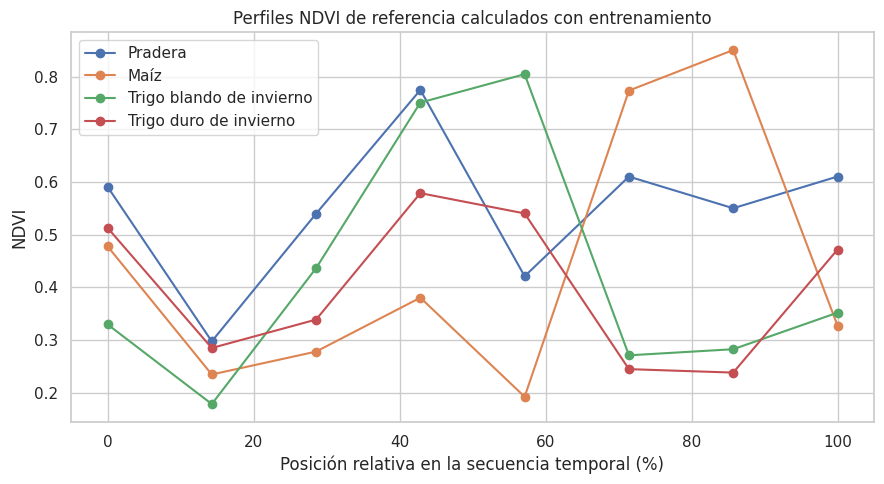

In [ ]:
# ==============================================================================
# E3.1 PREPARACIÓN DE SERIES NDVI Y PROTOTIPOS FENOLÓGICOS
# ==============================================================================

from collections import Counter

# Clases agrícolas presentes en entrenamiento y validación (sin Fondo ni Void).
conteos_train = Counter(y_train.astype(int).tolist())
conteos_val = Counter(y_val.astype(int).tolist())
clases_disponibles = [
    c for c in range(1, 19)
    if conteos_train[c] >= 40 and conteos_val[c] >= 15
]
clases_fenologia = sorted(
    clases_disponibles,
    key=lambda c: min(conteos_train[c], conteos_val[c]),
    reverse=True
)[:4]
assert len(clases_fenologia) >= 3, "La prueba requiere al menos tres clases agrícolas representadas."

N_PER_CLASE_TRAIN = 12
N_PER_CLASE_VAL = 3
N_PUNTOS_NDVI = 8


def curva_ndvi_pixel(imagen_s2, fila, columna, n_puntos=N_PUNTOS_NDVI):
    """Resume la serie NDVI de un píxel en posiciones temporales relativas."""
    rojo = np.maximum(imagen_s2[:, 2, fila, columna].astype(np.float32), 0.0)
    nir = np.maximum(imagen_s2[:, 6, fila, columna].astype(np.float32), 0.0)
    ndvi = np.divide(nir - rojo, np.maximum(nir + rojo, 1e-4))
    ndvi = np.clip(np.nan_to_num(ndvi, nan=0.0), -1.0, 1.0)
    return np.interp(
        np.linspace(0, 1, n_puntos),
        np.linspace(0, 1, len(ndvi)),
        ndvi
    ).astype(np.float32)


def extraer_muestras_fenologicas(ids, clases, max_por_clase, semilla):
    """Muestrea como máximo un píxel por clase y parche."""
    generador = np.random.default_rng(semilla)
    muestras = []
    conteo = {c: 0 for c in clases}

    for pid in generador.permutation(np.array(ids, dtype=int)):
        if all(conteo[c] >= max_por_clase for c in clases):
            break
        img = np.load(ruta_pastis(f"DATA_S2/S2_{int(pid)}.npy"), mmap_mode="r")
        etiqueta = np.load(ruta_pastis(f"ANNOTATIONS/TARGET_{int(pid)}.npy"), mmap_mode="r")[0]

        for clase in clases:
            if conteo[clase] >= max_por_clase:
                continue
            pixeles = np.argwhere(etiqueta == clase)
            if len(pixeles) < 10:
                continue
            fila, columna = pixeles[generador.integers(len(pixeles))]
            serie = curva_ndvi_pixel(img, int(fila), int(columna))
            if not np.isfinite(serie).all():
                continue
            muestras.append({
                "Patch": int(pid), "Clase": int(clase),
                "Serie": serie, "Fila": int(fila), "Columna": int(columna)
            })
            conteo[clase] += 1

    return muestras

muestras_train_fen = extraer_muestras_fenologicas(
    ids_elegidos["train"], clases_fenologia, N_PER_CLASE_TRAIN, SEED + 100
)
muestras_val_fen = extraer_muestras_fenologicas(
    ids_elegidos["val"], clases_fenologia, N_PER_CLASE_VAL, SEED + 200
)

# Se comparan únicamente las clases con muestras disponibles en ambas particiones.
clases_fenologia = [
    c for c in clases_fenologia
    if sum(m["Clase"] == c for m in muestras_train_fen) >= 3
    and sum(m["Clase"] == c for m in muestras_val_fen) >= 2
]
assert len(clases_fenologia) >= 3, "No se obtuvieron suficientes ejemplos fenológicos."
muestras_val_fen = [m for m in muestras_val_fen if m["Clase"] in clases_fenologia]

prototipos_fen = {
    clase: np.median(
        np.stack([m["Serie"] for m in muestras_train_fen if m["Clase"] == clase]),
        axis=0
    ).astype(np.float32)
    for clase in clases_fenologia
}

print("=== MUESTRA PARA LA PRUEBA FENOLÓGICA ===")
for c in clases_fenologia:
    print(f"{c:2d} | {NOMBRES_CLASES[c]:28s} | "
          f"Entrenamiento: {sum(m['Clase']==c for m in muestras_train_fen):2d} | "
          f"Validación: {sum(m['Clase']==c for m in muestras_val_fen):2d}")

plt.figure(figsize=(9, 5))
for clase in clases_fenologia:
    plt.plot(
        np.linspace(0, 100, N_PUNTOS_NDVI), prototipos_fen[clase],
        marker="o", label=NOMBRES_CLASES[clase]
    )
plt.title("Perfiles NDVI de referencia calculados con entrenamiento")
plt.xlabel("Posición relativa en la secuencia temporal (%)")
plt.ylabel("NDVI")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# ==============================================================================
# E3.2 GENERACIÓN DE DESCRIPCIONES FENOLÓGICAS CON MODELO DE LENGUAJE
# ==============================================================================

# Modelo instruccional abierto de 0.5B parámetros para una prueba breve en Colab.
import subprocess
import importlib.util

if importlib.util.find_spec("transformers") is None or importlib.util.find_spec("accelerate") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "transformers>=4.46,<5", "accelerate>=0.26"
    ])

from transformers import AutoModelForCausalLM, AutoTokenizer

MODELO_LLM = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer_fen = AutoTokenizer.from_pretrained(MODELO_LLM)
modelo_fen = AutoModelForCausalLM.from_pretrained(
    MODELO_LLM,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None
)
modelo_fen.eval()
if not torch.cuda.is_available():
    modelo_fen.to("cpu")


def describir_fenologia(serie):
    """Solicita una descripción de la curva sin proporcionar clases ni etiquetas."""
    numeros = ", ".join(f"{float(v):+.2f}" for v in serie)
    mensajes = [
        {"role": "system", "content": (
            "Eres analista de vegetación por satélite. Describe únicamente la "
            "evolución observada del NDVI usando solo ocho posiciones RELATIVAS "
            "de una curva interpolada. Las posiciones NO son días, semanas ni meses. "
            "No menciones unidades de tiempo, fechas, duración, lugares, especies "
            "ni causas. Describe en una oración breve el nivel inicial, la tendencia, "
            "el máximo y el nivel final. Usa 'inicio', 'mitad' y 'final'."
        )},
        {"role": "user", "content": (
            f"NDVI en ocho posiciones relativas equidistantes (no días): {numeros}. "
            "Describe únicamente la forma de la curva, sin fechas ni duraciones."
        )}
    ]
    prompt = tokenizer_fen.apply_chat_template(
        mensajes, tokenize=False, add_generation_prompt=True
    )
    entradas = tokenizer_fen(prompt, return_tensors="pt")
    entradas = {k: v.to(modelo_fen.device) for k, v in entradas.items()}
    with torch.inference_mode():
        tokens = modelo_fen.generate(
            **entradas,
            max_new_tokens=55,
            do_sample=False,
            pad_token_id=tokenizer_fen.eos_token_id
        )
    nuevos = tokens[0, entradas["input_ids"].shape[-1]:]
    return tokenizer_fen.decode(nuevos, skip_special_tokens=True).strip()

inicio_llm = time.time()
textos_referencia = {
    clase: describir_fenologia(prototipos_fen[clase])
    for clase in clases_fenologia
}
textos_validacion = [
    describir_fenologia(m["Serie"]) for m in muestras_val_fen
]
tiempo_llm = time.time() - inicio_llm

print("=== DESCRIPCIONES FENOLÓGICAS GENERADAS ===")
for clase in clases_fenologia:
    print(f"\n{NOMBRES_CLASES[clase]}: {textos_referencia[clase]}")
print(f"\nTextos de validación generados: {len(textos_validacion)}")
print(f"Tiempo total de generación: {tiempo_llm:.1f} segundos")

# Auditoría de posibles referencias temporales inexistentes en la salida del LLM.
patron_duracion = re.compile(
    r"\b(?:d[ií]a[s]?|semana[s]?|mes(?:es)?|año[s]?|hora[s]?|fecha[s]?)\b",
    flags=re.IGNORECASE
)
textos_a_auditar = list(textos_referencia.values()) + textos_validacion
n_duraciones = sum(bool(patron_duracion.search(t)) for t in textos_a_auditar)
print(f"Menciones de duración no sustentada: {n_duraciones}/{len(textos_a_auditar)}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

=== DESCRIPCIONES FENOLÓGICAS GENERADAS ===

Pradera: La curva interpolada muestra un aumento gradual desde -0.59 hasta +0.61, con un máximo de +0.61 y un nivel final de +0.77.

Maíz: La curva interpolada muestra un aumento gradual desde -0.48 hasta +0.85, con un máximo de +0.85 y un nivel final de +0.85.

Trigo blando de invierno: La curva interpolada muestra un aumento gradual desde -0.33 hasta +0.80, con un máximo de +0.75 y un nivel final de +0.80.

Trigo duro de invierno: La curva interpolada muestra un aumento gradual desde -0.51 hasta +0.47, con un máximo de +0.64 y un nivel final de +0.54.

Textos de validación generados: 12
Tiempo total de generación: 22.8 segundos
Menciones de duración no sustentada: 0/16


=== COMPARACIÓN EXPLORATORIA EN VALIDACIÓN ===


,Método,Accuracy,Macro F1
0,Distancia entre curvas NDVI,0.5833,0.5762
1,Descripciones LLM + TF-IDF,0.2500,0.1667


,Clase real,Predicción LLM,Predicción NDVI,Descripción generada
0,Pradera,Trigo duro de invierno,Maíz,La curva interpolada muestra un aumento gradua...
1,Maíz,Trigo blando de invierno,Maíz,La curva interpolada muestra un aumento gradua...
2,Trigo blando de invierno,Trigo duro de invierno,Trigo blando de invierno,La curva interpolada muestra un aumento gradua...
3,Pradera,Trigo duro de invierno,Pradera,La curva interpolada muestra un aumento gradua...
4,Maíz,Trigo duro de invierno,Pradera,La curva interpolada muestra un aumento gradua...
5,Maíz,Trigo duro de invierno,Maíz,La curva interpolada muestra un aumento gradua...
6,Trigo blando de invierno,Trigo blando de invierno,Trigo duro de invierno,La curva interpolada muestra un aumento gradua...
7,Trigo blando de invierno,Trigo blando de invierno,Trigo duro de invierno,La curva interpolada muestra un aumento gradua...
8,Pradera,Trigo blando de invierno,Pradera,La curva interpolada muestra un aumento gradua...
9,Trigo duro de invierno,Trigo blando de invierno,Trigo duro de invierno,La curva interpolada muestra un aumento gradua...


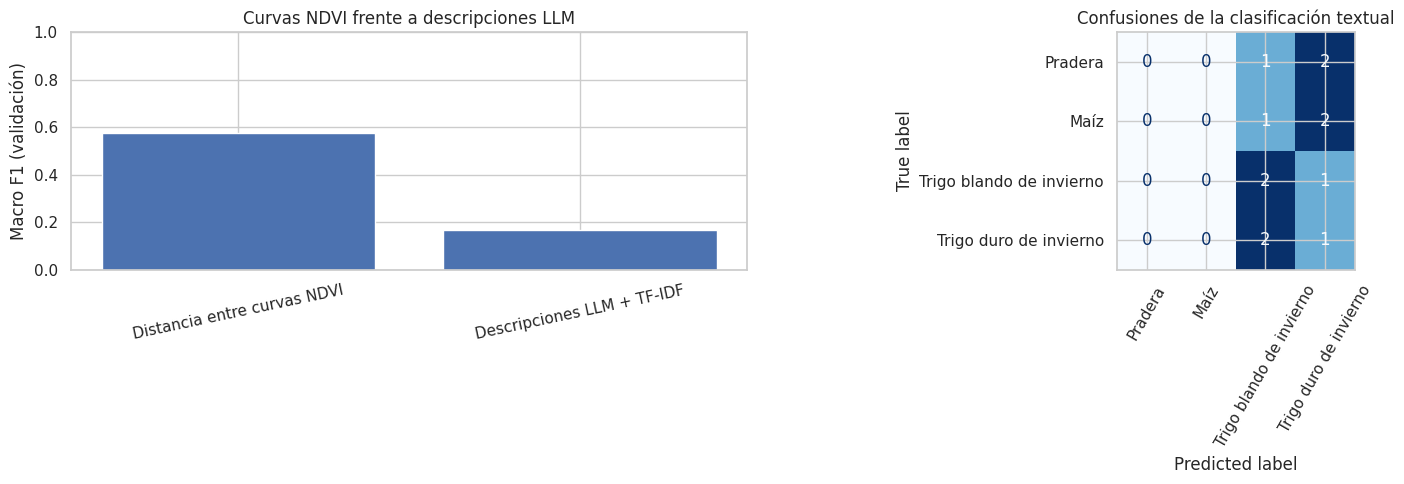

In [ ]:
# ==============================================================================
# E3.3 CLASIFICACIÓN POR SIMILITUD TEXTUAL Y COMPARACIÓN NUMÉRICA
# ==============================================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import ConfusionMatrixDisplay

etiquetas_fen = np.array(clases_fenologia, dtype=int)
y_fen_real = np.array([m["Clase"] for m in muestras_val_fen], dtype=int)
series_fen_val = np.stack([m["Serie"] for m in muestras_val_fen])
series_fen_train = np.stack([m["Serie"] for m in muestras_train_fen
                            if m["Clase"] in clases_fenologia])

# Clasificador textual: cada descripción de validación se asigna al perfil más próximo.
referencias_texto = [textos_referencia[c] for c in clases_fenologia]
vectorizador = TfidfVectorizer(analyzer="char", ngram_range=(2, 5))
texto_referencia_vectorizado = vectorizador.fit_transform(referencias_texto)
texto_validacion_vectorizado = vectorizador.transform(textos_validacion)
similitudes = cosine_similarity(
    texto_validacion_vectorizado,
    texto_referencia_vectorizado
)
y_fen_texto = etiquetas_fen[np.argmax(similitudes, axis=1)]

# Referencia sin LLM: vecino más cercano entre las curvas NDVI agregadas por clase.
mu_fen = series_fen_train.mean(axis=0)
sigma_fen = np.maximum(series_fen_train.std(axis=0), 0.05)
V = (series_fen_val - mu_fen) / sigma_fen
P = (np.stack([prototipos_fen[c] for c in clases_fenologia]) - mu_fen) / sigma_fen
distancias = ((V[:, None, :] - P[None, :, :]) ** 2).mean(axis=2)
y_fen_numerico = etiquetas_fen[np.argmin(distancias, axis=1)]

comparacion_fen = pd.DataFrame([
    {"Método": "Distancia entre curvas NDVI", "Accuracy": accuracy_score(y_fen_real, y_fen_numerico),
     "Macro F1": f1_score(y_fen_real, y_fen_numerico, labels=clases_fenologia,
                          average="macro", zero_division=0)},
    {"Método": "Descripciones LLM + TF-IDF", "Accuracy": accuracy_score(y_fen_real, y_fen_texto),
     "Macro F1": f1_score(y_fen_real, y_fen_texto, labels=clases_fenologia,
                          average="macro", zero_division=0)}
]).sort_values("Macro F1", ascending=False)

print("=== COMPARACIÓN EXPLORATORIA EN VALIDACIÓN ===")
display(comparacion_fen.round(4))

# Ejemplos de textos y predicciones para examinar los aciertos y las confusiones.
ejemplos_fen = pd.DataFrame({
    "Clase real": [NOMBRES_CLASES[c] for c in y_fen_real],
    "Predicción LLM": [NOMBRES_CLASES[c] for c in y_fen_texto],
    "Predicción NDVI": [NOMBRES_CLASES[c] for c in y_fen_numerico],
    "Descripción generada": textos_validacion,
})
display(ejemplos_fen.head(12))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(comparacion_fen["Método"], comparacion_fen["Macro F1"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Macro F1 (validación)")
axes[0].set_title("Curvas NDVI frente a descripciones LLM")
axes[0].tick_params(axis="x", rotation=12)

cm_fen = confusion_matrix(y_fen_real, y_fen_texto, labels=clases_fenologia)
ConfusionMatrixDisplay(
    confusion_matrix=cm_fen,
    display_labels=[NOMBRES_CLASES[c] for c in clases_fenologia]
).plot(ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=60)
axes[1].set_title("Confusiones de la clasificación textual")
plt.tight_layout()
plt.show()



## E4. Interpretación de las Pruebas Complementarias

Las pruebas complementarias permitieron evaluar tres alternativas relacionadas con la selección de características y la aplicación de modelos de aprendizaje profundo al problema de identificación de cultivos.

En primer lugar, la comparación entre 52 y cinco características mostró una disminución importante del desempeño al reducir las variables. El LDA con 52 características obtuvo un Macro F1 de **0.3933**, mientras que utilizando únicamente las cinco características más influyentes alcanzó **0.1735**. Este resultado indica que, aunque algunas variables tienen una mayor contribución individual, las demás también contienen información relevante para distinguir las clases de cultivo.

En la prueba con **U-Net**, el modelo presentó una reducción progresiva de la pérdida de entrenamiento, pasando de 2.8174 a 1.9159 durante seis épocas. Sin embargo, su desempeño en prueba fue limitado, con un Macro F1 de **0.0950** y un Macro IoU de **0.0664**. Estos resultados muestran que fue posible implementar y entrenar una red neuronal para segmentación semántica, aunque la cantidad reducida de patches y las características utilizadas todavía no permiten obtener un desempeño competitivo.

Finalmente, se realizó una prueba basada en el artículo *“Phenology description is all you need!”*, utilizando un modelo de lenguaje para generar descripciones de la evolución temporal del NDVI. La clasificación mediante las descripciones generadas por **Qwen y TF-IDF** obtuvo un Macro F1 de **0.1667**, mientras que la comparación directa entre curvas NDVI alcanzó **0.5762**.

Adicionalmente, se identificaron algunas inconsistencias numéricas en los textos generados. Por ejemplo, ciertas descripciones mencionaron valores finales superiores al máximo reportado para la misma curva. Esto muestra que transformar información espectral y temporal a lenguaje natural puede introducir imprecisiones o pérdida de información.

En conjunto, los resultados indican que las pruebas con U-Net y el modelo de lenguaje son técnicamente viables, pero en las condiciones evaluadas no mostraron ventajas frente a sus métodos de referencia. También es importante señalar que estos experimentos utilizaron muestras reducidas y configuraciones diferentes, por lo que sus métricas no deben compararse directamente con las obtenidas por los ensambles del modelo principal.

### Referencias

- Assran, M., et al. (2023). *Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture*. CVPR.
- Wen, S., Zhao, W., Ji, F., Peng, R., Zhang, L., & Wang, Q. (2025). *“Phenology description is all you need!” Mapping unknown crop types with remote sensing time-series and LLM generated text alignment*. *ISPRS Journal of Photogrammetry and Remote Sensing, 228*, 141–165. https://doi.org/10.1016/j.isprsjprs.2025.07.002


In [ ]:
# ==============================================================================
# E4.1 RESUMEN CUANTITATIVO DE LAS PRUEBAS COMPLEMENTARIAS
# ==============================================================================
resumen_extra = f"""
**Comparación de características:** el LDA con 52 características registró
Macro F1 de **{m52['Macro F1']:.4f}**, frente a **{m5['Macro F1']:.4f}**
con las cinco características, sobre la misma muestra de entrenamiento y validación.

**U-Net:** con {len(ids_unet['train'])} patches de entrenamiento y {EPOCHS} épocas,
registró en prueba **Macro F1 = {m_unet_test['Macro F1']:.4f}**,
**Macro IoU = {m_unet_test['Macro IoU']:.4f}** y
**Accuracy = {m_unet_test['Accuracy']:.4f}**, evaluando solo los píxeles válidos.

**Fenología:** para {len(clases_fenologia)} clases y {len(y_fen_real)}
observaciones de validación, la distancia directa entre curvas NDVI alcanzó
Macro F1 de **{comparacion_fen.loc[comparacion_fen['Método'] == 'Distancia entre curvas NDVI', 'Macro F1'].iloc[0]:.4f}**,
mientras que las descripciones generadas mediante LLM y TF-IDF alcanzaron
**{comparacion_fen.loc[comparacion_fen['Método'] == 'Descripciones LLM + TF-IDF', 'Macro F1'].iloc[0]:.4f}**.
Las ocho posiciones de cada curva son relativas, no unidades de calendario.
"""
display(Markdown(resumen_extra))


**Comparación de características:** el LDA con 52 características registró
Macro F1 de **0.3933**, frente a **0.1735**
con las cinco características, sobre la misma muestra de entrenamiento y validación.

**U-Net:** con 16 patches de entrenamiento y 6 épocas,
registró en prueba **Macro F1 = 0.0950**,
**Macro IoU = 0.0664** y
**Accuracy = 0.4645**, evaluando solo los píxeles válidos.

**Fenología:** para 4 clases y 12
observaciones de validación, la distancia directa entre curvas NDVI alcanzó
Macro F1 de **0.5762**,
mientras que las descripciones generadas mediante LLM y TF-IDF alcanzaron
**0.1667**.
Las ocho posiciones de cada curva son relativas, no unidades de calendario.


## Declaración sobre el uso de herramientas de inteligencia artificial

**Equipo:** 13  
**Integrantes:**
- José Eduardo De Moraes López - A01634782
- André Zaragoza Bonilla - A01797076
- David Alejandro Velázquez Valdéz - A01632648

**Actividad:** Avance 5. Modelo final

**Herramientas de IA utilizadas:** ChatGPT (OpenAI, GPT-6, 2026).

**Uso declarado:**
- Apoyo en la organización del código de los ensambles homogéneos y heterogéneos, principalmente en la implementación de `RandomizedSearchCV`, `VotingClassifier` y `StackingClassifier` de scikit-learn.
- Apoyo para estructurar las visualizaciones de desempeño, incluyendo matriz de confusión, curvas ROC y Precisión–Recall, e importancia de características por permutación.
- Consulta de conceptos y apoyo en la implementación de la U-Net y de la prueba de descripciones fenológicas con un modelo de lenguaje, tomando como referencia la literatura de segmentación y alineación de series temporales con texto.
- Apoyo en la redacción y organización de las explicaciones metodológicas incluidas en la libreta.

**Verificación y responsabilidad del equipo:**
- El equipo mantiene como referencia los resultados y las decisiones metodológicas de los Avances 3 y 4, incluidas las particiones oficiales de PASTIS y la selección de Macro F1 como métrica principal.
- La comparación y selección de modelos se realiza mediante las métricas definidas en el código, utilizando el conjunto de validación y reservando el de prueba para la evaluación final.
- La interpretación de las métricas, la revisión de los resultados obtenidos y las conclusiones presentadas corresponden a la responsabilidad académica de los integrantes del equipo.

**Contribución individual del equipo:**
- **José Eduardo De Moraes López:** integración de los modelos individuales de referencia, configuración y comparación de los ensambles homogéneos.
- **André Zaragoza Bonilla:** implementación de Voting y Stacking, optimización de hiperparámetros y análisis de los resultados comparativos.
- **David Alejandro Velázquez Valdéz:** cálculo y visualización de métricas, interpretación del desempeño por clase y desarrollo de las pruebas exploratorias con cinco características, U-Net y descripciones fenológicas generadas con un modelo de lenguaje.

**Decisiones principales:**
- **Métrica principal de selección:** se mantuvo Macro F1 debido al desbalance de clases agrícolas. Se descartó seleccionar exclusivamente por Accuracy, ya que puede favorecer a las clases mayoritarias.
- **Comparación de estrategias de ensamble:** se evaluaron tanto métodos homogéneos como heterogéneos sobre los mismos conjuntos de datos. Se descartó limitar la comparación a una sola familia de modelos, porque no permitiría valorar las ventajas de combinar algoritmos diferentes.
- **Prueba complementaria de segmentación:** se seleccionaron cinco características por importancia por permutación para la U-Net y se incorporó una comparación de perfiles NDVI mediante descripciones de un modelo de lenguaje. Se descartó combinar sus métricas con las de los ensambles porque los ejercicios emplean muestras y representaciones diferentes.